In [8]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as mp


In [1]:
import os
print(os.getcwd())

C:\Users\pavit


In [9]:
a = pd.read_csv('Sales_Data.csv')
print(a.head(3))


  ProductCategory Region CustomerSegment IsPromotionApplied  ProductionCost  \
0       Furniture   East     High Income                Yes      536.051521   
1            Toys   West     High Income                 No      352.701361   
2     Electronics  South     High Income                 No      618.989105   

   MarketingSpend  SeasonalDemandIndex  CompetitorPrice  CustomerRating  \
0      189.277811             1.159611       220.831351        4.035607   
1      255.921497             1.545366       467.217175        4.106804   
2      277.399353             1.671902       363.623261        4.021775   

   EconomicIndex  StoreCount  SalesRevenue  
0     146.225757          52   2293.143707  
1     104.261304          35   1640.454368  
2      77.220752          44   2173.086023  


In [10]:
print(a)


     ProductCategory Region CustomerSegment IsPromotionApplied  \
0          Furniture   East     High Income                Yes   
1               Toys   West     High Income                 No   
2        Electronics  South     High Income                 No   
3          Furniture   West   Middle Income                Yes   
4          Furniture   West   Middle Income                Yes   
...              ...    ...             ...                ...   
1995     Electronics   West     High Income                Yes   
1996        Clothing   West   Middle Income                 No   
1997     Electronics  South      Low Income                Yes   
1998       Furniture  South     High Income                 No   
1999     Electronics  South      Low Income                Yes   

      ProductionCost  MarketingSpend  SeasonalDemandIndex  CompetitorPrice  \
0         536.051521      189.277811             1.159611       220.831351   
1         352.701361      255.921497             1.

In [11]:
b = pd.DataFrame(a)
b

,ProductCategory,Region,CustomerSegment,IsPromotionApplied,ProductionCost,MarketingSpend,SeasonalDemandIndex,CompetitorPrice,CustomerRating,EconomicIndex,StoreCount,SalesRevenue
0,Furniture,East,High Income,Yes,536.051521,189.277811,1.159611,220.831351,4.035607,146.225757,52,2293.143707
1,Toys,West,High Income,No,352.701361,255.921497,1.545366,467.217175,4.106804,104.261304,35,1640.454368
2,Electronics,South,High Income,No,618.989105,277.399353,1.671902,363.623261,4.021775,77.220752,44,2173.086023
3,Furniture,West,Middle Income,Yes,339.959644,153.557699,1.408244,209.853621,4.148890,128.277455,15,1672.608857
4,Furniture,West,Middle Income,Yes,477.951385,155.814478,2.177301,274.859950,4.913782,111.309643,61,2443.222482
...,...,...,...,...,...,...,...,...,...,...,...,...
1995,Electronics,West,High Income,Yes,517.717323,232.614735,0.975678,322.583207,5.041142,91.441434,17,1936.541701
1996,Clothing,West,Middle Income,No,450.390738,209.679267,1.563159,245.091794,3.720744,127.068979,83,2108.352980
1997,Electronics,South,Low Income,Yes,588.046636,189.616137,1.585797,342.856222,4.449142,130.946380,91,2721.300846
1998,Furniture,South,High Income,No,246.240212,124.049514,0.378380,367.191579,3.848678,92.705192,51,1281.359345


In [12]:
rows = len(b.axes[0])
cols = len(b.axes[1])
print("Number of Rows: " + str(rows))
print("Number of Columns: " + str(cols))

Number of Rows: 2000
Number of Columns: 12


In [13]:
column_names_index = b.columns
print(column_names_index)

Index(['ProductCategory', 'Region', 'CustomerSegment', 'IsPromotionApplied',
       'ProductionCost', 'MarketingSpend', 'SeasonalDemandIndex',
       'CompetitorPrice', 'CustomerRating', 'EconomicIndex', 'StoreCount',
       'SalesRevenue'],
      dtype='object')


In [14]:

categorical_vars = ['ProductCategory', 'Region', 'CustomerSegment', 'IsPromotionApplied']
def money_stats(group):
    return pd.Series({
        'Sum': group.sum(),
        'Average': group.mean(),
        'Median': group.median(),
        'Range': group.max() - group.min(),
        'Q1': group.quantile(0.25),
        'Q3': group.quantile(0.75)
    })
grouped_stats = b.groupby(categorical_vars)['SalesRevenue'].apply(money_stats).unstack()
grouped_stats.head(10)
grouped_stats.tail(30)


Sum  \
ProductCategory Region CustomerSegment IsPromotionApplied                 
Furniture       West   High Income     No                  42227.899708   
                                       Yes                 34115.690230   
                       Low Income      No                  33374.318655   
                                       Yes                 47982.173997   
                       Middle Income   No                  51302.927918   
                                       Yes                 30272.814691   
Toys            East   High Income     No                  41154.880010   
                                       Yes                 34170.484093   
                       Low Income      No                  42418.675037   
                                       Yes                 46438.494605   
                       Middle Income   No                  34224.880319   
                                       Yes                 41870.886434   
                North  High Income     No                  41869.613918   
                                       Yes                 45682.807921   
                       Low Income      No                  34777.725981   
                                       Yes                 41911.641855   
                       Middle Income   No                  43488.479081   
                                       Yes                 35538.044835   
                South  High Income     No                  46442.070564   
                                       Yes                 31394.946663   
                       Low Income      No                  33446.288934   
                                       Yes                 52606.876555   
                       Middle Income   No                  42394.878508   
                                       Yes                 31979.695833   
                West   High Income     No                  36156.916203   
                                       Yes                 51148.394177   
                       Low Income      No                  47073.061843   
                                       Yes                 52258.131601   
                       Middle Income   No                  48657.710169   
                                       Yes                 49470.050719   

                                                               Average  \
ProductCategory Region CustomerSegment IsPromotionApplied                
Furniture       West   High Income     No                  1919.449987   
                                       Yes                 2132.230639   
                       Low Income      No                  2085.894916   
                                       Yes                 2086.181478   
                       Middle Income   No                  2137.621997   
                                       Yes                 2018.187646   
Toys            East   High Income     No                  1959.756191   
                                       Yes                 2010.028476   
                       Low Income      No                  1928.121593   
                                       Yes                 2110.840664   
                       Middle Income   No                  2013.228254   
                                       Yes                 1993.851735   
                North  High Income     No                  2093.480696   
                                       Yes                 2076.491269   
                       Low Income      No                  2045.748587   
                                       Yes                 2095.582093   
                       Middle Income   No                  2174.423954   
                                       Yes                 2090.473226   
                South  High Income     No                  1935.086274   
                                       Yes                 2092.996444   
                       Low Income      

In [15]:
#CATEGORICAL ANALYSIS FOR 1 OR 2 COLUMNS
categories_vars = ['ProductCategory']
def single_stats(each):
    return pd.Series({
        'Sum': each.sum(),
        'Average': each.mean(),
        'Median': each.median(),
        'Range': each.max() - each.min(),
        'Q1': each.quantile(0.25),
        'Q3': each.quantile(0.75)
    })
single_stats = b.groupby(categories_vars)['SalesRevenue'].apply(single_stats).unstack()
single_stats.head(10)


,Sum,Average,Median,Range,Q1,Q3
ProductCategory,,,,,,
Clothing,1.025784e+06,2080.697888,2073.750111,1855.904256,1820.836180,2334.501377
Electronics,1.103738e+06,2102.357517,2090.817242,1814.459482,1841.133043,2365.127441
Furniture,1.009618e+06,2056.247473,2062.489483,1612.485686,1795.212741,2322.439758
Toys,1.006576e+06,2050.052212,2038.546487,1842.087182,1797.630862,2322.229043


In [16]:
categories_vars = ['IsPromotionApplied']
def single_stats(each):
    return pd.Series({
        'Sum': each.sum(),
        'Average': each.mean(),
        'Median': each.median(),
        'Range': each.max() - each.min(),
        'Q1': each.quantile(0.25),
        'Q3': each.quantile(0.75)
    })
single_stats = b.groupby(categories_vars)['SalesRevenue'].apply(single_stats).unstack()
single_stats.head(10)

,Sum,Average,Median,Range,Q1,Q3
IsPromotionApplied,,,,,,
No,2.126143e+06,2068.232303,2068.173855,1825.138404,1814.111567,2328.519016
Yes,2.019572e+06,2077.749067,2067.491207,2020.595705,1799.704504,2352.632623


In [17]:
categories_vars = ['Region']
def single_stats(each):
    return pd.Series({
        'Sum': each.sum(),
        'Average': each.mean(),
        'Median': each.median(),
        'Range': each.max() - each.min(),
        'Q1': each.quantile(0.25),
        'Q3': each.quantile(0.75)
    })
single_stats = b.groupby(categories_vars)['SalesRevenue'].apply(single_stats).unstack()
single_stats.head(10)

,Sum,Average,Median,Range,Q1,Q3
Region,,,,,,
East,9.623489e+05,2065.126325,2060.808372,1955.766579,1796.573643,2340.196488
North,1.071621e+06,2097.105750,2083.605655,1575.178778,1838.767246,2368.377545
South,1.061640e+06,2057.441917,2043.738358,1903.558172,1813.092636,2313.941591
West,1.050105e+06,2071.212949,2085.905639,1842.087182,1797.899005,2343.092031


In [18]:
categories_vars = ['CustomerSegment']
def single_stats(each):
    return pd.Series({
        'Sum': each.sum(),
        'Average': each.mean(),
        'Median': each.median(),
        'Range': each.max() - each.min(),
        'Q1': each.quantile(0.25),
        'Q3': each.quantile(0.75)
    })
single_stats = b.groupby(categories_vars)['SalesRevenue'].apply(single_stats).unstack()
single_stats.head(10)

,Sum,Average,Median,Range,Q1,Q3
CustomerSegment,,,,,,
High Income,1.376682e+06,2067.090737,2055.445394,1655.555074,1798.356466,2347.413467
Low Income,1.454480e+06,2068.961451,2076.505701,2020.595705,1811.945297,2334.150560
Middle Income,1.314553e+06,2083.284578,2073.452566,1955.766579,1830.373174,2351.562582


In [19]:
categories_vars = ['IsPromotionApplied','Region']
def single_stats(each):
    return pd.Series({
        'Sum': each.sum(),
        'Average': each.mean(),
        'Median': each.median(),
        'Range': each.max() - each.min(),
        'Q1': each.quantile(0.25),
        'Q3': each.quantile(0.75)
    })
single_stats = b.groupby(categories_vars)['SalesRevenue'].apply(single_stats).unstack()
single_stats.head(10)

Sum      Average       Median  \
IsPromotionApplied Region                                            
No                 East    496699.486584  2078.240530  2066.883047   
                   North   546597.514813  2094.243352  2080.565929   
                   South   530742.595342  2041.317674  2025.894231   
                   West    552103.210390  2060.086606  2099.458664   
Yes                East    465649.380739  2051.318858  2041.622147   
                   North   525023.523529  2100.094094  2089.720089   
                   South   530897.433972  2073.818101  2060.209989   
                   West    498001.754625  2083.689350  2083.718974   

                                 Range           Q1           Q3  
IsPromotionApplied Region                                         
No                 East    1825.138404  1807.465198  2358.856967  
                   North   1575.178778  1854.334305  2354.075599  
                   South   1677.056601  1809.688082  2278.824933  
                   West    1677.395733  1798.247499  2330.112250  
Yes                East    1720.651263  1759.005309  2335.534504  
                   North   1477.760108  1819.321199  2379.447573  
                   South   1817.276036  1827.192706  2349.096013  
                   West    1719.102686  1796.151156  2356.181914

In [20]:
categories_vars = ['IsPromotionApplied','CustomerSegment']
def single_stats(each):
    return pd.Series({
        'Sum': each.sum(),
        'Average': each.mean(),
        'Median': each.median(),
        'Range': each.max() - each.min(),
        'Q1': each.quantile(0.25),
        'Q3': each.quantile(0.75)
    })
single_stats = b.groupby(categories_vars)['SalesRevenue'].apply(single_stats).unstack()
single_stats.head(10)

Sum      Average       Median  \
IsPromotionApplied CustomerSegment                                            
No                 High Income      712351.932749  2064.788211  2049.428757   
                   Low Income       715898.019522  2051.283724  2065.890878   
                   Middle Income    697892.854859  2089.499565  2083.564418   
Yes                High Income      664330.498201  2069.565415  2058.273698   
                   Low Income       738581.880736  2086.389494  2088.864160   
                   Middle Income    616659.713928  2076.295333  2052.692902   

                                          Range           Q1           Q3  
IsPromotionApplied CustomerSegment                                         
No                 High Income      1655.555074  1798.351325  2330.745548  
                   Low Income       1714.730588  1816.611409  2300.342837  
                   Middle Income    1825.138404  1842.936644  2366.522068  
Yes                High Income      1536.036706  1799.974230  2353.615649  
                   Low Income       2020.595705  1804.175469  2366.635861  
                   Middle Income    1792.547125  1797.405224  2333.583694

In [21]:
categories_vars = ['IsPromotionApplied', 'ProductCategory']
def single_stats(each):
    return pd.Series({
        'Sum': each.sum(),
        'Average': each.mean(),
        'Median': each.median(),
        'Range': each.max() - each.min(),
        'Q1': each.quantile(0.25),
        'Q3': each.quantile(0.75)
    })
single_stats = b.groupby(categories_vars)['SalesRevenue'].apply(single_stats).unstack()
single_stats.head(10)

Sum      Average       Median  \
IsPromotionApplied ProductCategory                                            
No                 Clothing         520496.960801  2073.693071  2070.564923   
                   Electronics      589386.710944  2104.952539  2102.299411   
                   Furniture        524153.954817  2055.505705  2071.716011   
                   Toys             492105.180568  2033.492482  2007.739589   
Yes                Clothing         505287.097976  2087.963215  2090.001495   
                   Electronics      514350.985361  2099.391777  2083.718974   
                   Furniture        485463.554236  2057.048959  2052.099122   
                   Toys             514470.455293  2066.146407  2080.339511   

                                          Range           Q1           Q3  
IsPromotionApplied ProductCategory                                         
No                 Clothing         1700.547171  1821.681872  2319.401035  
                   Electronics      1636.141898  1859.417335  2362.854740  
                   Furniture        1612.485686  1801.194072  2297.787379  
                   Toys             1801.986966  1784.108101  2304.060028  
Yes                Clothing         1800.963038  1807.686952  2371.739284  
                   Electronics      1726.328959  1823.643050  2369.413945  
                   Furniture        1481.247639  1785.030282  2337.867717  
                   Toys             1717.286398  1802.657400  2340.845869

In [22]:
categories_vars = ['Region','ProductCategory']
def single_stats(each):
    return pd.Series({
        'Sum': each.sum(),
        'Average': each.mean(),
        'Median': each.median(),
        'Range': each.max() - each.min(),
        'Q1': each.quantile(0.25),
        'Q3': each.quantile(0.75)
    })
single_stats = b.groupby(categories_vars)['SalesRevenue'].apply(single_stats).unstack()
single_stats.head(10)

Sum      Average       Median        Range  \
Region ProductCategory                                                         
East   Clothing         229081.788778  2027.272467  1970.392329  1590.023088   
       Electronics      266614.964362  2167.601336  2195.588316  1666.553447   
       Furniture        226373.813684  2057.943761  2031.722919  1560.187515   
       Toys             240278.300499  2002.319171  1983.981542  1670.046210   
North  Clothing         263631.171458  2092.310885  2064.728461  1475.047273   
       Electronics      308406.920232  2112.376166  2085.778921  1507.530705   
       Furniture        256314.633061  2083.858805  2118.502178  1521.108530   
       Toys             243268.313591  2097.140634  2081.339437  1377.896189   
South  Clothing         261127.260657  2105.865005  2105.354656  1800.963038   
       Electronics      274594.774490  2096.143317  2073.329612  1525.933683   

                                 Q1           Q3  
Region ProductCategory                            
East   Clothing         1779.725546  2267.671001  
       Electronics      1901.484702  2403.235700  
       Furniture        1805.740262  2349.103526  
       Toys             1753.007109  2285.281664  
North  Clothing         1807.477470  2366.977558  
       Electronics      1840.607900  2363.347171  
       Furniture        1822.897217  2376.803855  
       Toys             1853.558566  2371.545166  
South  Clothing         1917.092019  2316.430160  
       Electronics      1865.715090  2348.865262

In [23]:
categories_vars = ['Region','CustomerSegment']
def single_stats(each):
    return pd.Series({
        'Sum': each.sum(),
        'Average': each.mean(),
        'Median': each.median(),
        'Range': each.max() - each.min(),
        'Q1': each.quantile(0.25),
        'Q3': each.quantile(0.75)
    })
single_stats = b.groupby(categories_vars)['SalesRevenue'].apply(single_stats).unstack()
single_stats.head(10)

Sum      Average       Median        Range  \
Region CustomerSegment                                                         
East   High Income      316128.610157  2052.783183  2020.911153  1593.345787   
       Low Income       348834.289278  2064.108221  2112.565545  1626.740224   
       Middle Income    297385.967889  2079.622153  2061.382095  1955.766579   
North  High Income      370915.318853  2095.566773  2071.629232  1477.760108   
       Low Income       360108.382972  2105.896976  2118.651957  1525.263974   
       Middle Income    340597.336517  2089.554212  2056.554589  1500.307673   
South  High Income      346666.329248  2039.213701  2028.417572  1607.253376   
       Low Income       371669.628954  2053.423364  2048.520193  1839.188393   
       Middle Income    343304.071112  2080.630734  2044.183493  1651.335771   
West   High Income      342972.172692  2078.619228  2099.704471  1655.555074   

                                 Q1           Q3  
Region CustomerSegment                            
East   High Income      1780.992731  2319.230391  
       Low Income       1789.805729  2334.290252  
       Middle Income    1812.765579  2376.325838  
North  High Income      1808.822329  2403.641669  
       Low Income       1856.992684  2360.708372  
       Middle Income    1840.541657  2340.041812  
South  High Income      1805.513334  2293.430722  
       Low Income       1788.209527  2305.902034  
       Middle Income    1834.767858  2327.607574  
West   High Income      1762.416909  2376.557067

In [24]:
b


,ProductCategory,Region,CustomerSegment,IsPromotionApplied,ProductionCost,MarketingSpend,SeasonalDemandIndex,CompetitorPrice,CustomerRating,EconomicIndex,StoreCount,SalesRevenue
0,Furniture,East,High Income,Yes,536.051521,189.277811,1.159611,220.831351,4.035607,146.225757,52,2293.143707
1,Toys,West,High Income,No,352.701361,255.921497,1.545366,467.217175,4.106804,104.261304,35,1640.454368
2,Electronics,South,High Income,No,618.989105,277.399353,1.671902,363.623261,4.021775,77.220752,44,2173.086023
3,Furniture,West,Middle Income,Yes,339.959644,153.557699,1.408244,209.853621,4.148890,128.277455,15,1672.608857
4,Furniture,West,Middle Income,Yes,477.951385,155.814478,2.177301,274.859950,4.913782,111.309643,61,2443.222482
...,...,...,...,...,...,...,...,...,...,...,...,...
1995,Electronics,West,High Income,Yes,517.717323,232.614735,0.975678,322.583207,5.041142,91.441434,17,1936.541701
1996,Clothing,West,Middle Income,No,450.390738,209.679267,1.563159,245.091794,3.720744,127.068979,83,2108.352980
1997,Electronics,South,Low Income,Yes,588.046636,189.616137,1.585797,342.856222,4.449142,130.946380,91,2721.300846
1998,Furniture,South,High Income,No,246.240212,124.049514,0.378380,367.191579,3.848678,92.705192,51,1281.359345


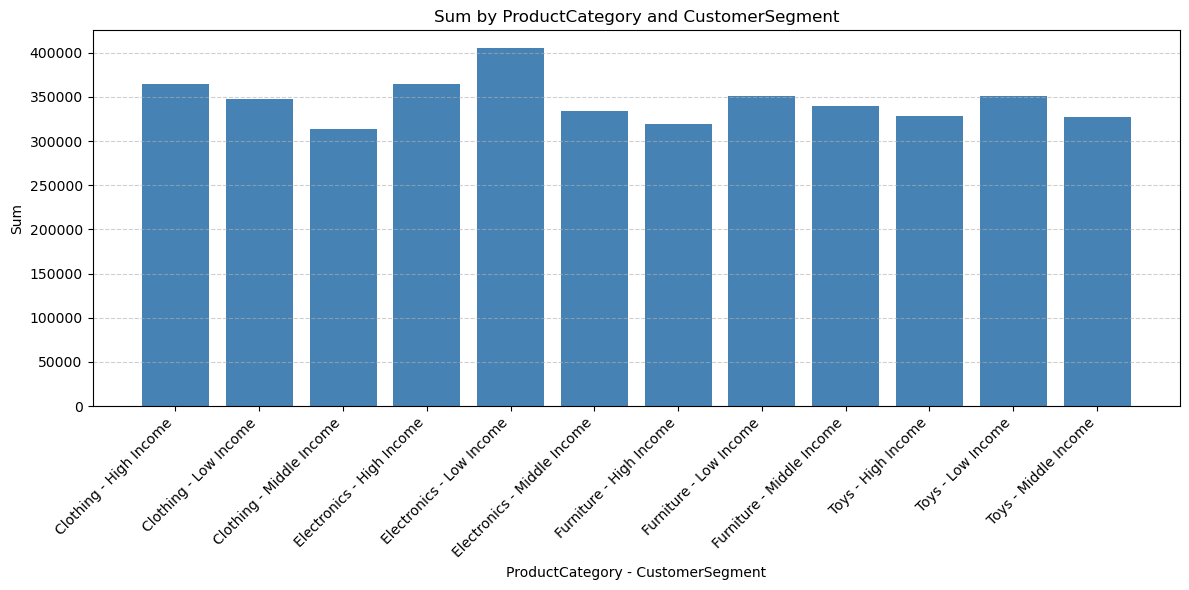

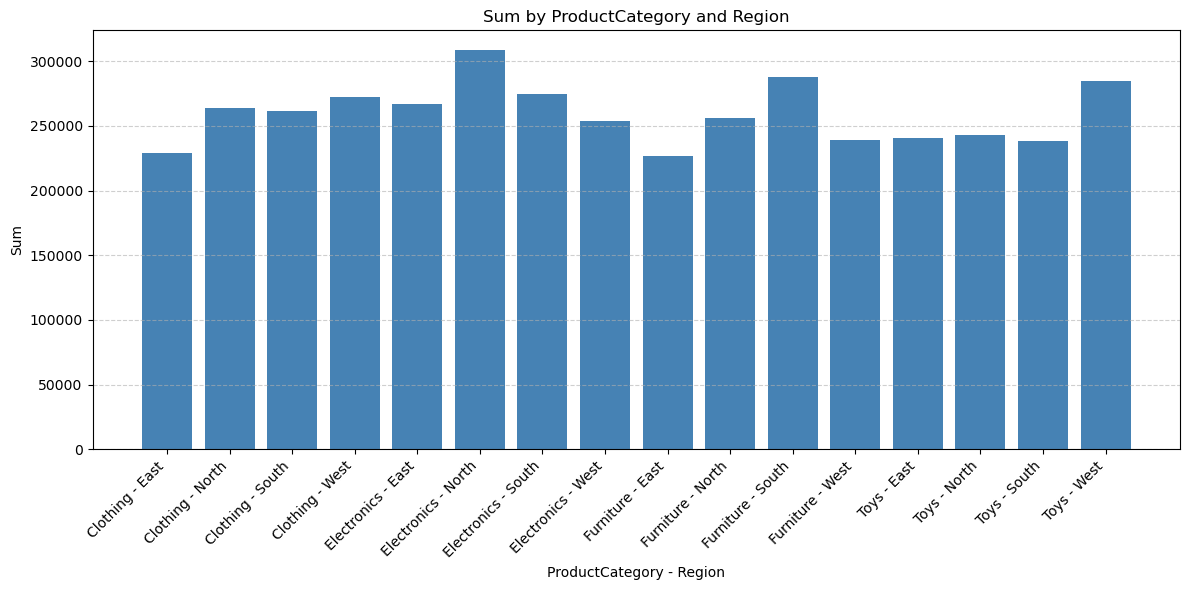

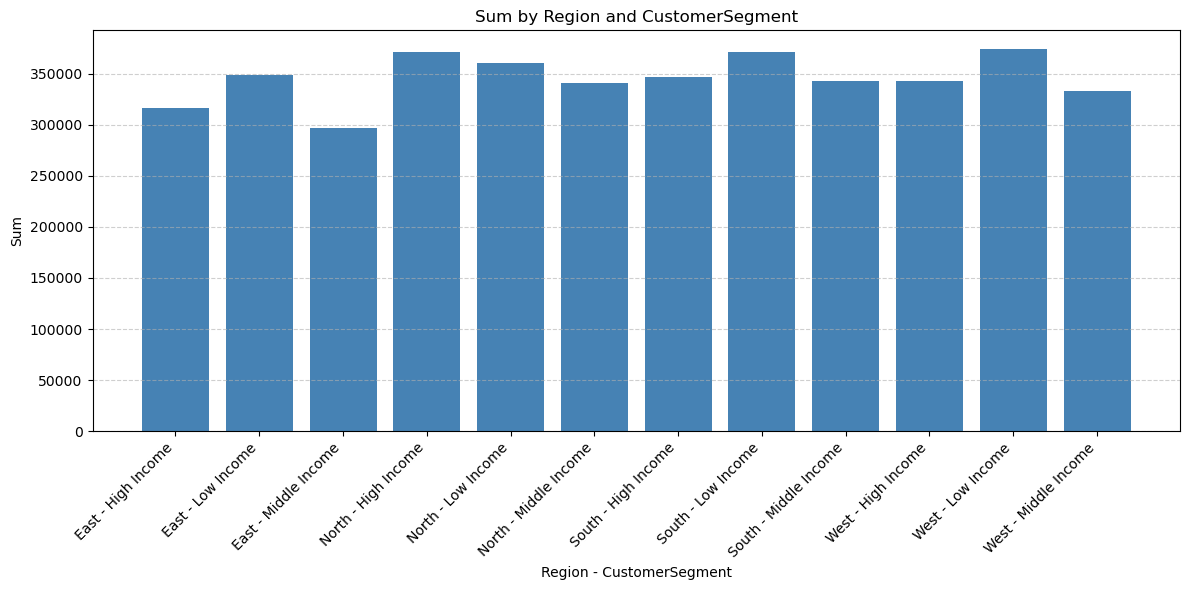

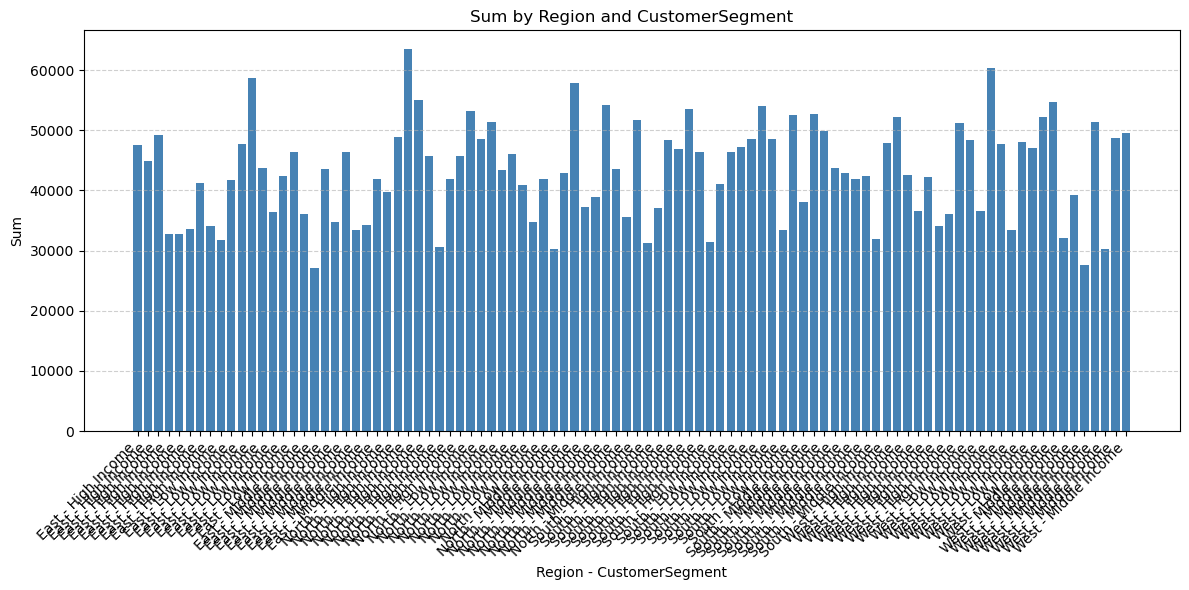

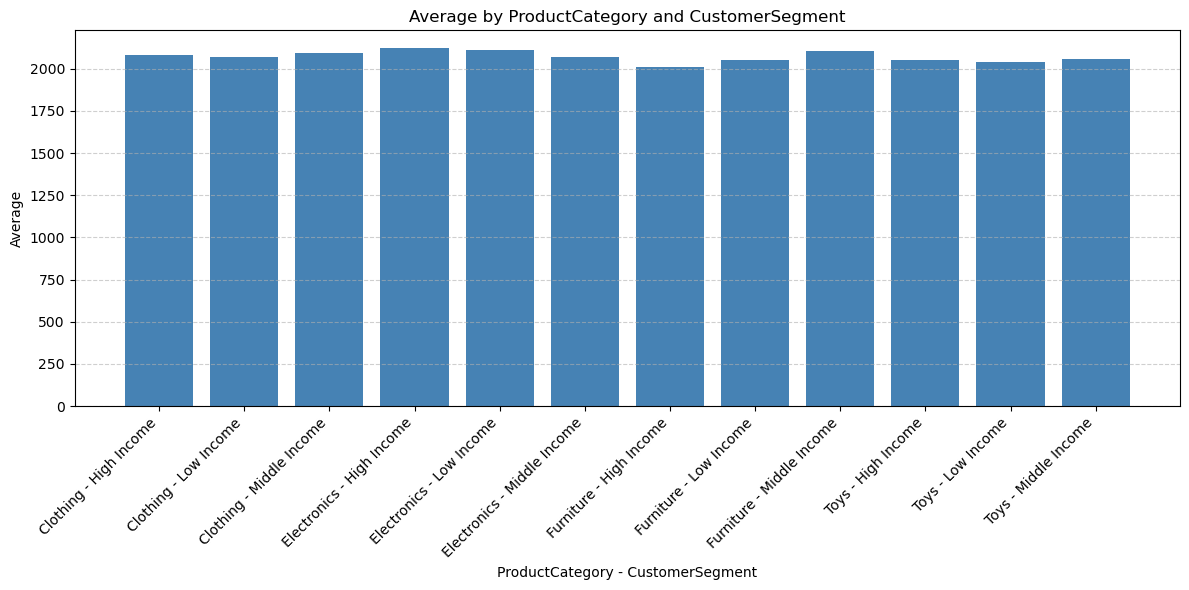

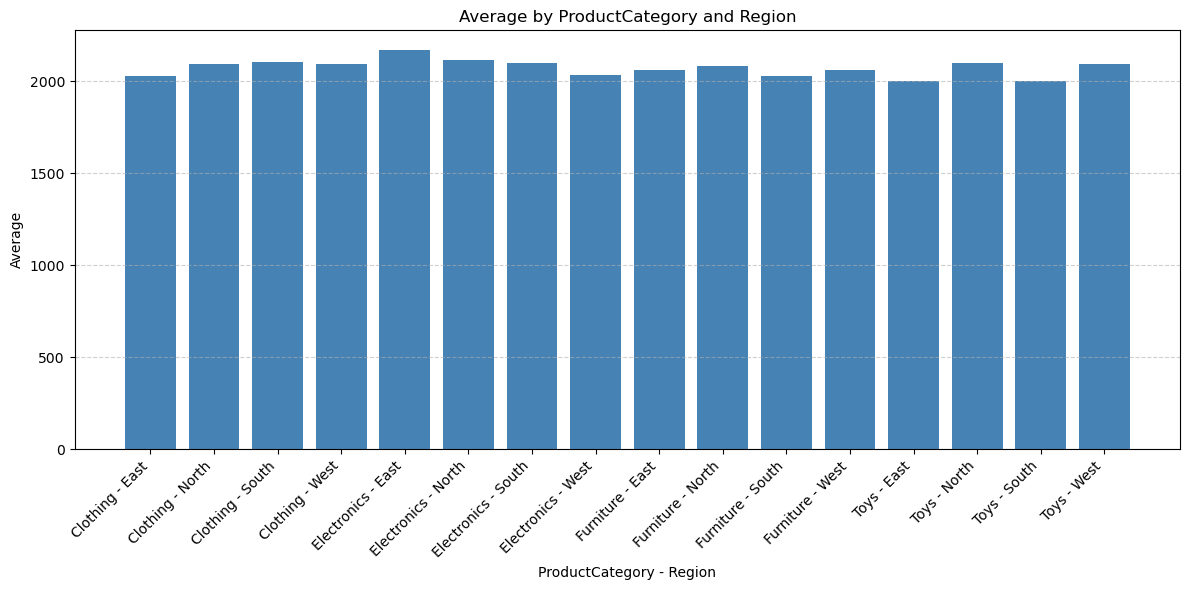

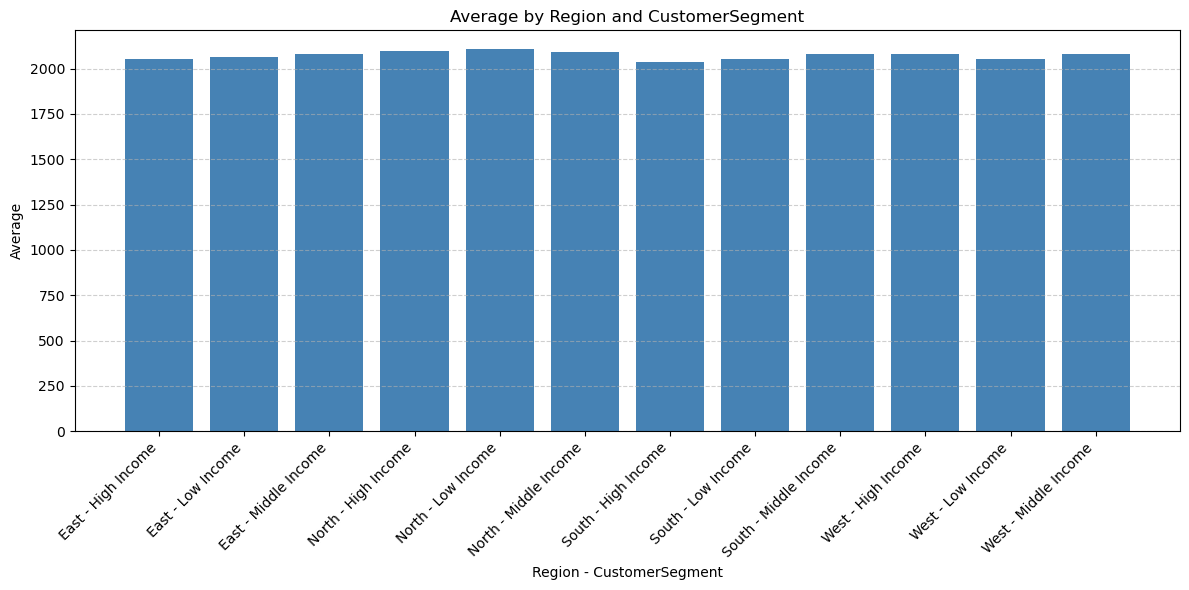

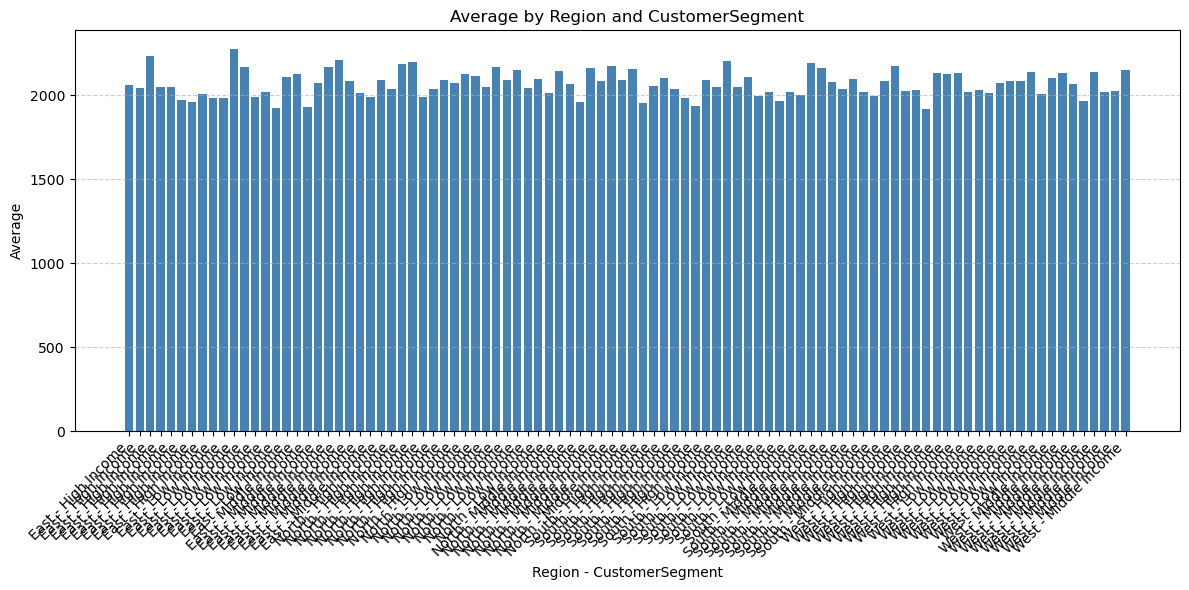

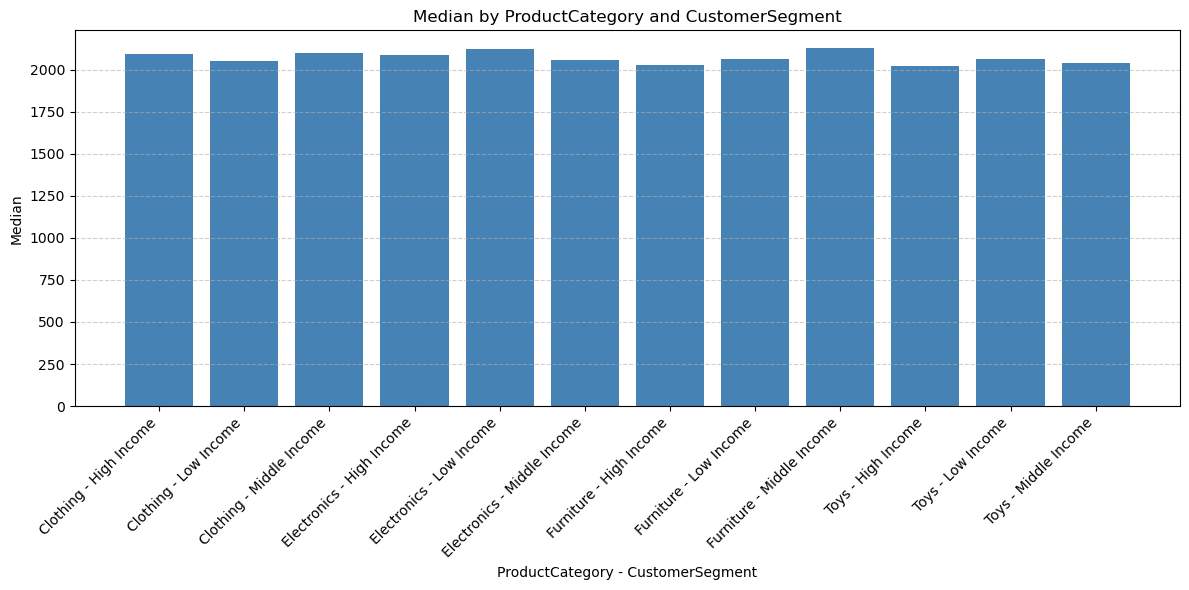

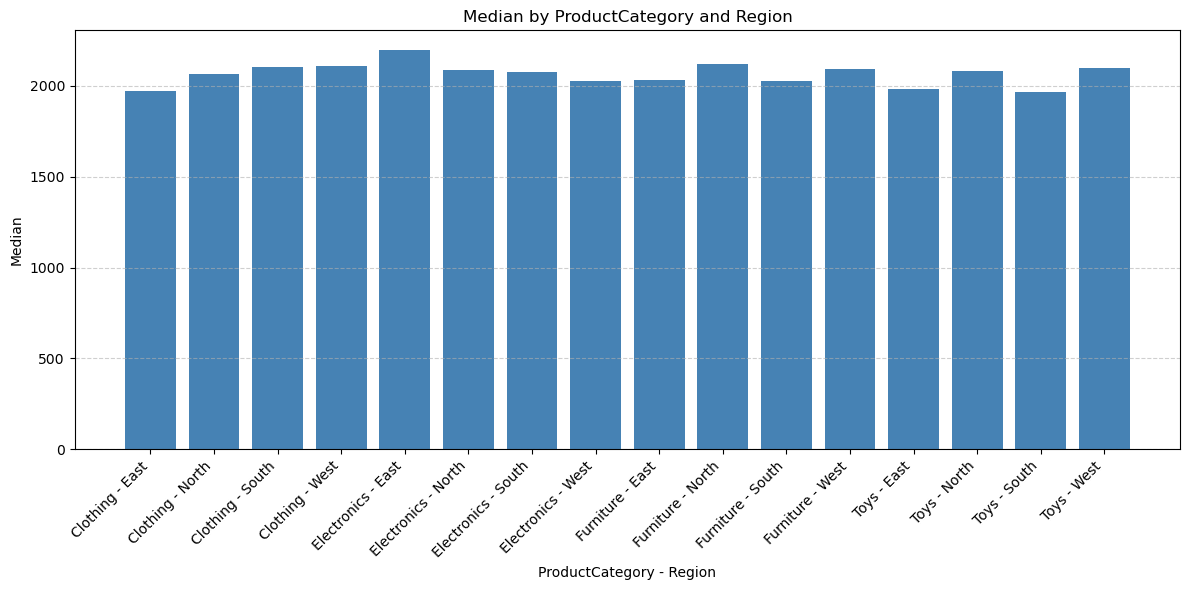

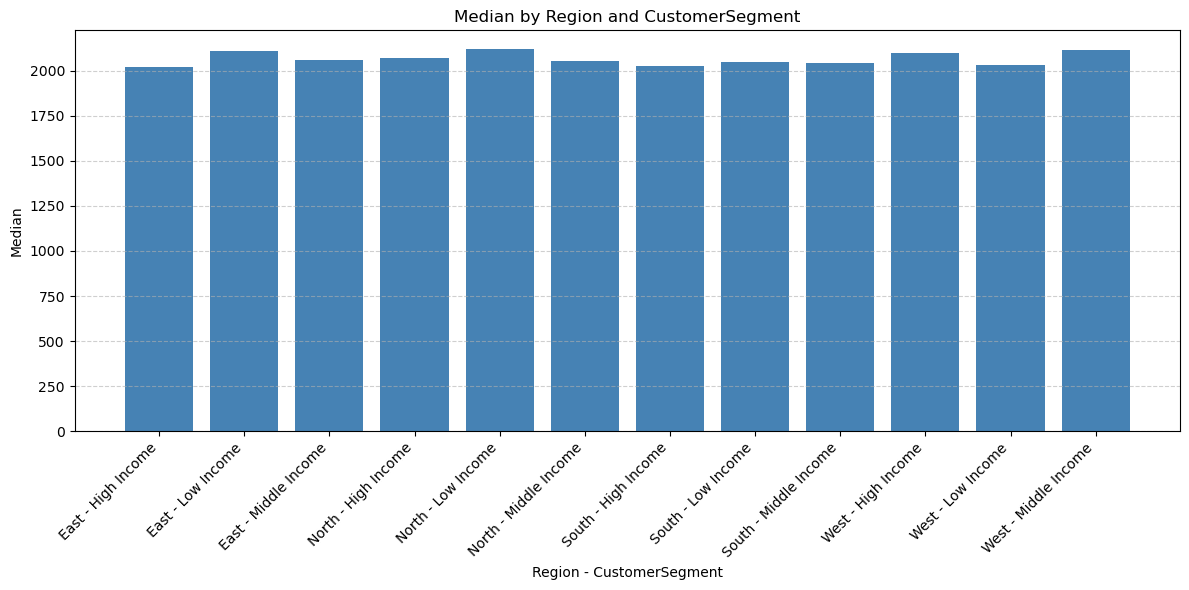

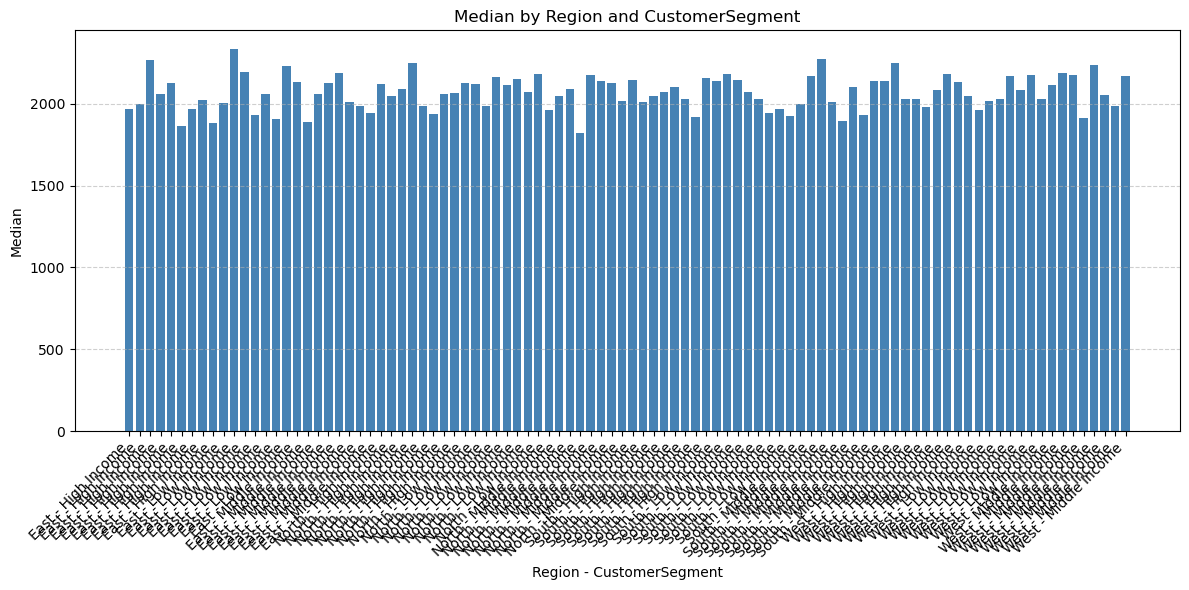

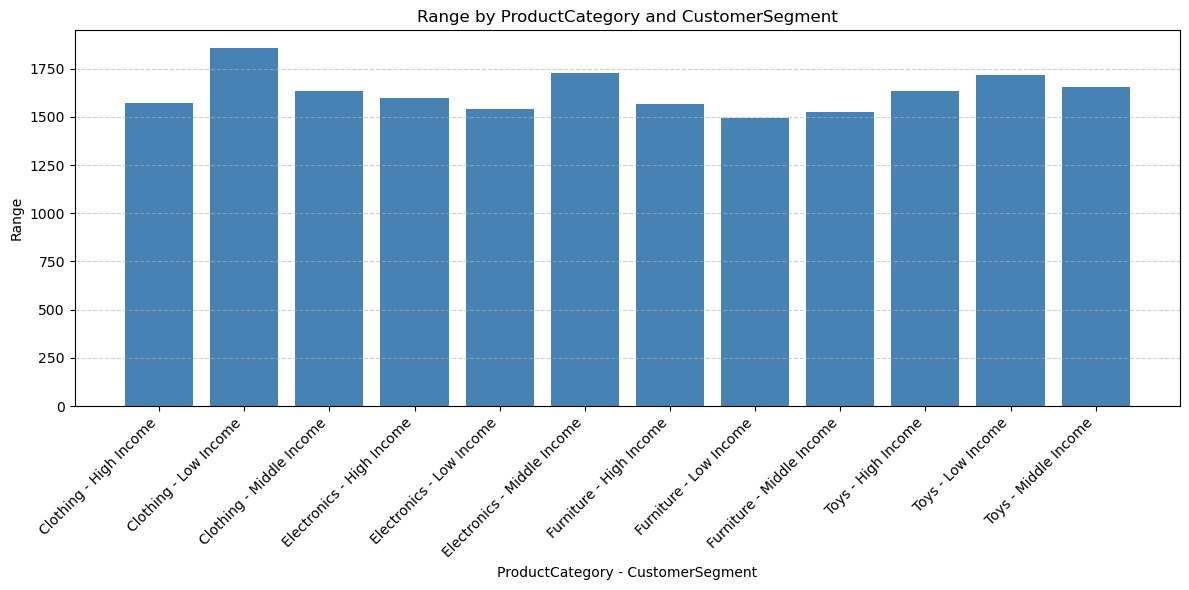

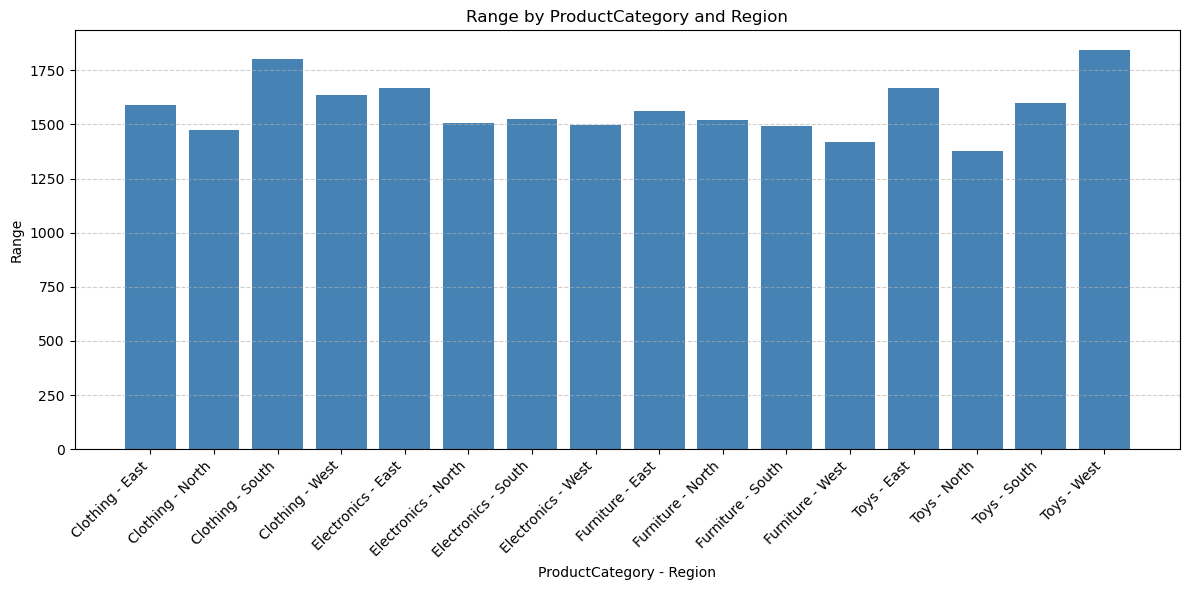

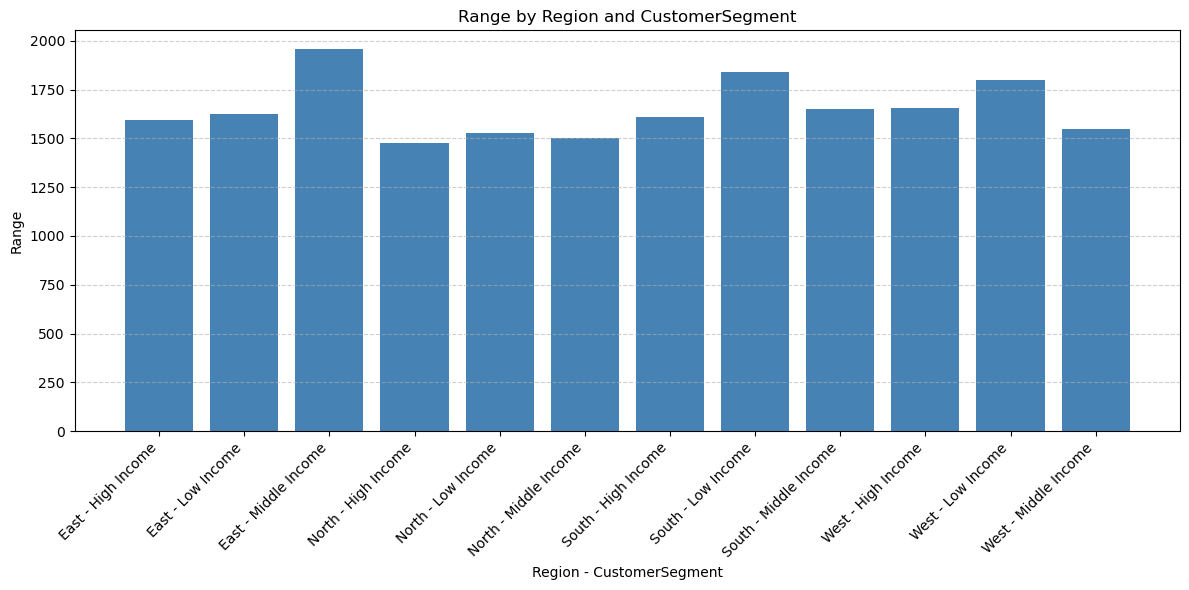

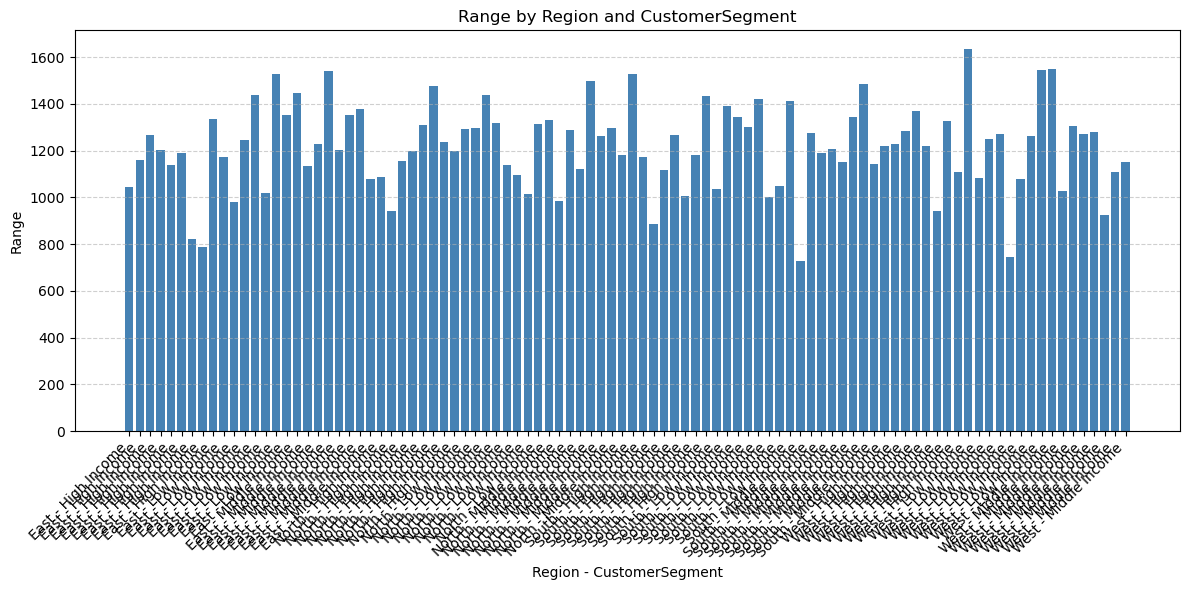

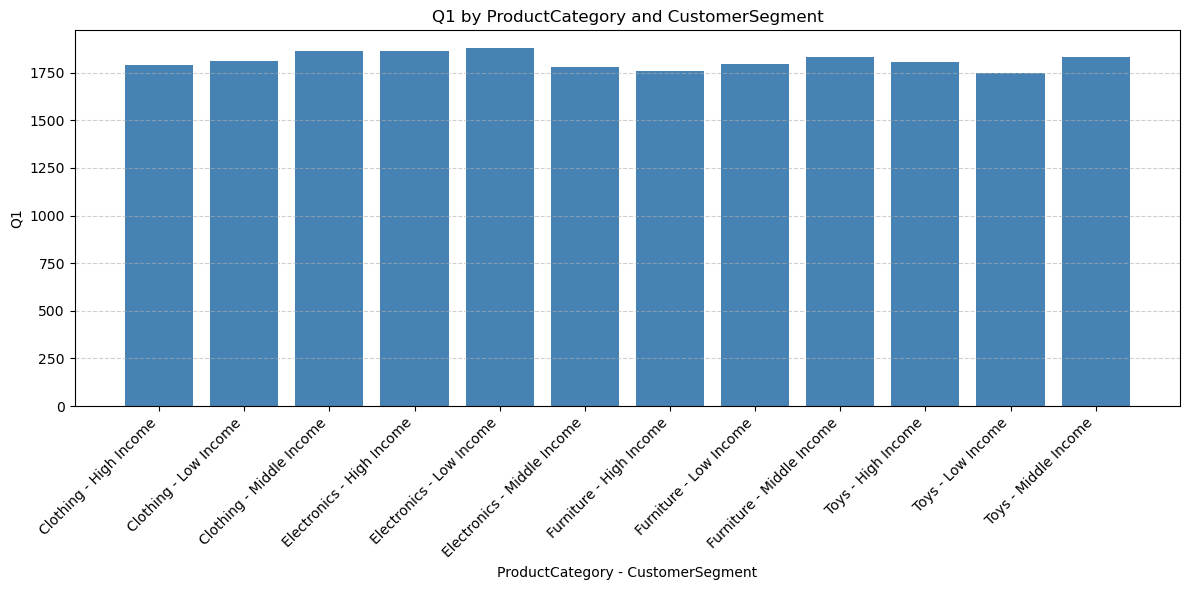

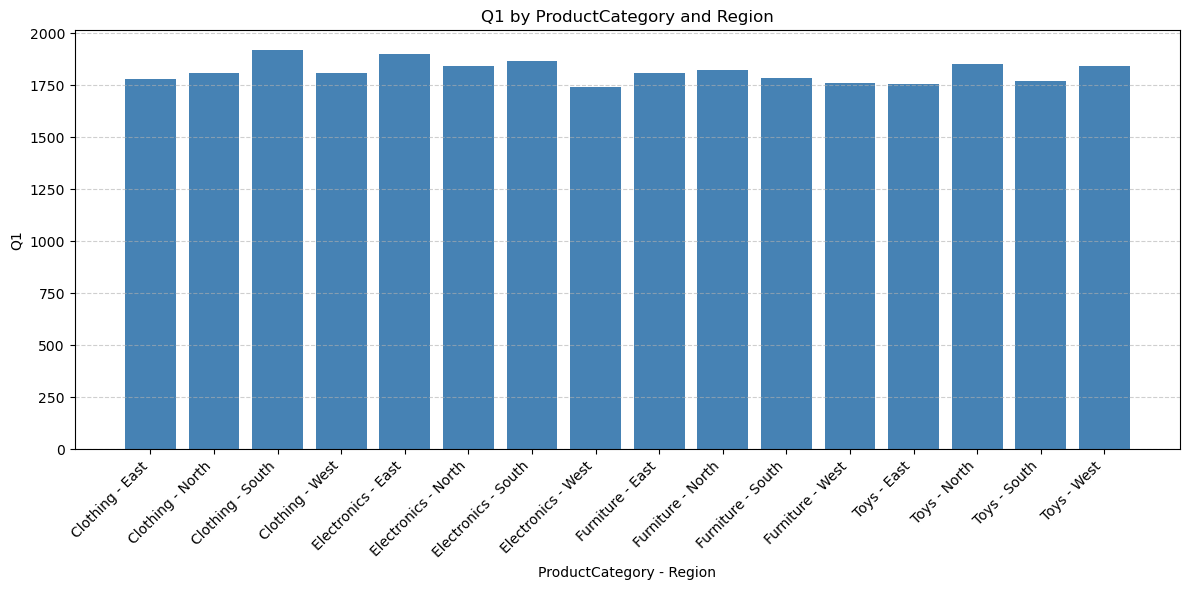

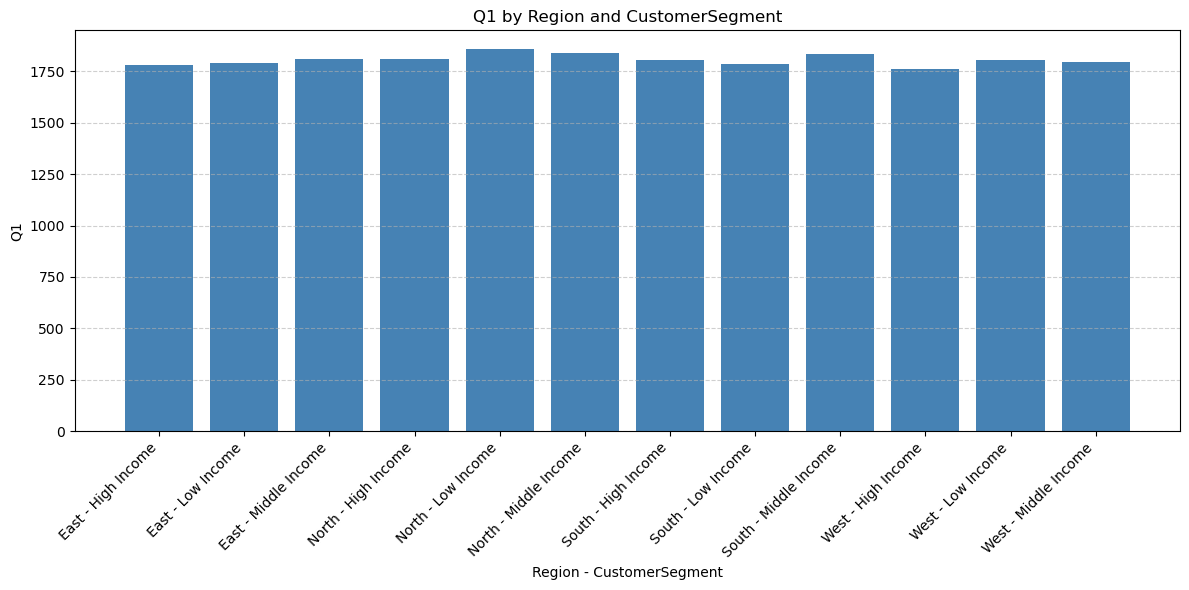

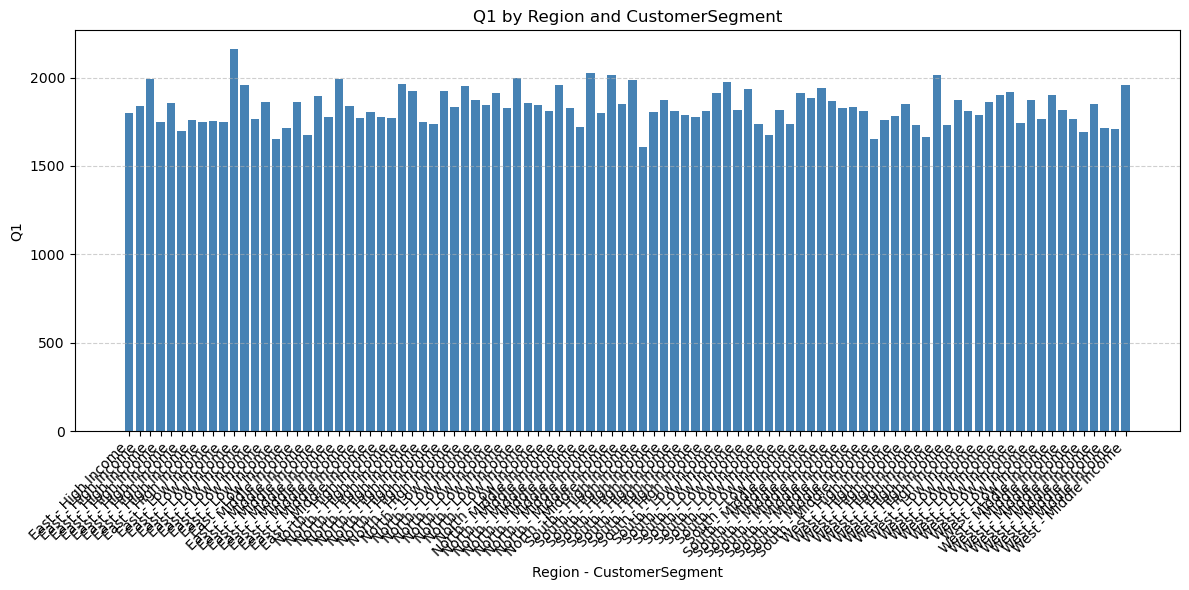

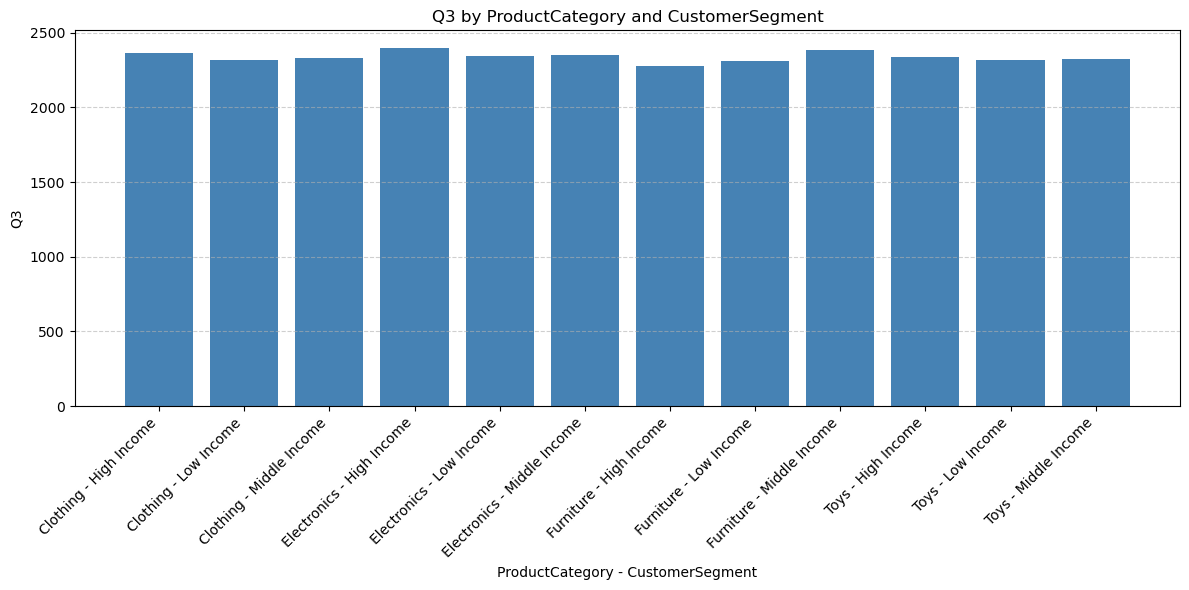

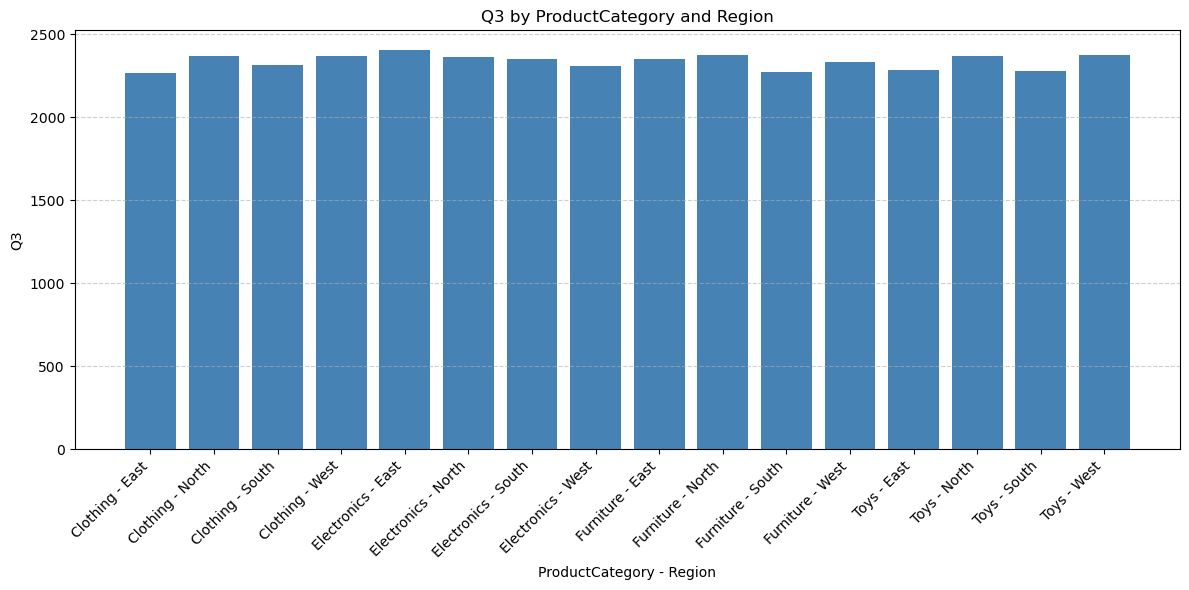

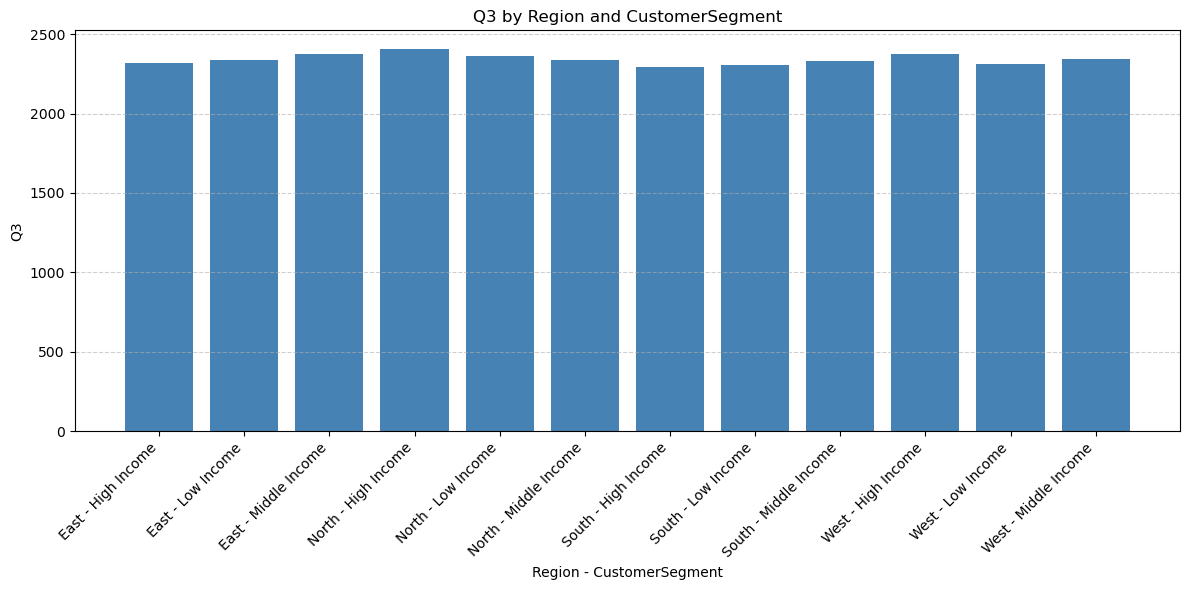

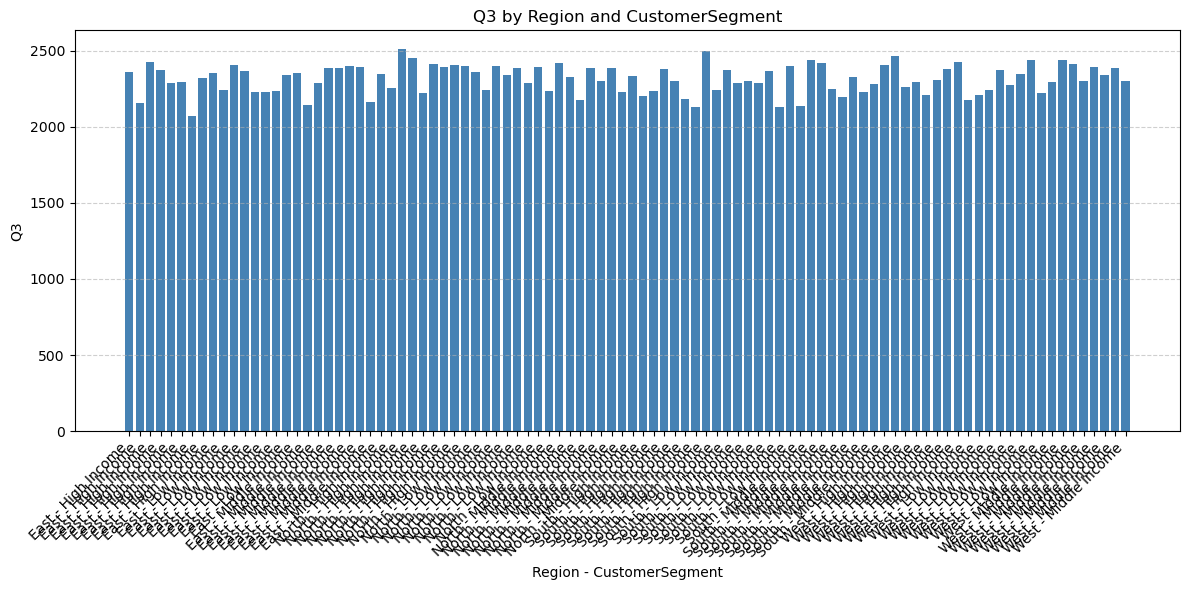

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("Sales_Data.csv")


def summarize_by(group_cols):
    grouped = df.groupby(group_cols)['SalesRevenue']
    summary = grouped.agg([
        'sum',
        'mean',
        'median',
        lambda x: x.max() - x.min(),
        lambda x: x.quantile(0.25),
        lambda x: x.quantile(0.75)
    ])
    summary.columns = ['Sum', 'Average', 'Median', 'Range', 'Q1', 'Q3']
    return summary.reset_index()


summary1 = summarize_by(['ProductCategory', 'CustomerSegment'])
summary2 = summarize_by(['ProductCategory', 'Region'])
summary3 = summarize_by(['Region', 'CustomerSegment'])
summary4 = summarize_by(['Region', 'CustomerSegment', 'ProductCategory','IsPromotionApplied'])

def plot_bar_chart(df, group_cols, value_col):
    labels = df[group_cols[0]].astype(str) + " - " + df[group_cols[1]].astype(str)
    values = df[value_col]

    plt.figure(figsize=(12, 6))
    x = np.arange(len(labels))
    plt.bar(x, values, color='steelblue')
    plt.xticks(x, labels, rotation=45, ha='right')
    plt.title(f'{value_col} by {group_cols[0]} and {group_cols[1]}')
    plt.xlabel(f'{group_cols[0]} - {group_cols[1]}')
    plt.ylabel(value_col)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

for col in ['Sum', 'Average', 'Median', 'Range', 'Q1', 'Q3']:
    plot_bar_chart(summary1, ['ProductCategory', 'CustomerSegment'], col)
    plot_bar_chart(summary2, ['ProductCategory', 'Region'], col)
    plot_bar_chart(summary3, ['Region', 'CustomerSegment'], col)
    plot_bar_chart(summary4, ['Region', 'CustomerSegment','ProductCategory', 'IsPromotionApplied'], col)
    


C:\Users\pavit\AppData\Local\Temp\ipykernel_9384\4156088181.py:31: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base_colors = plt.cm.get_cmap('tab20', len(unique_labels)).colors


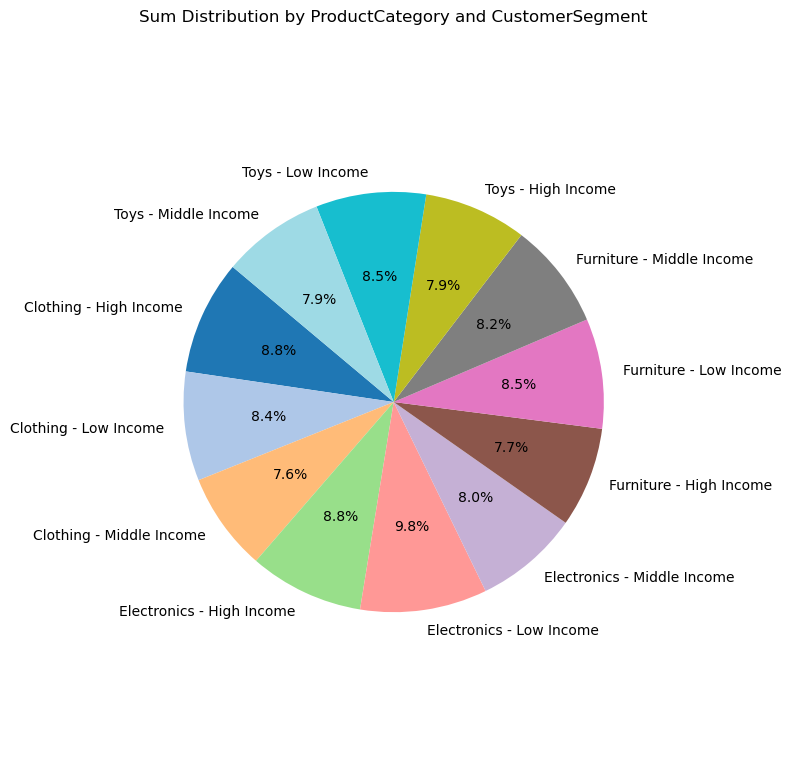

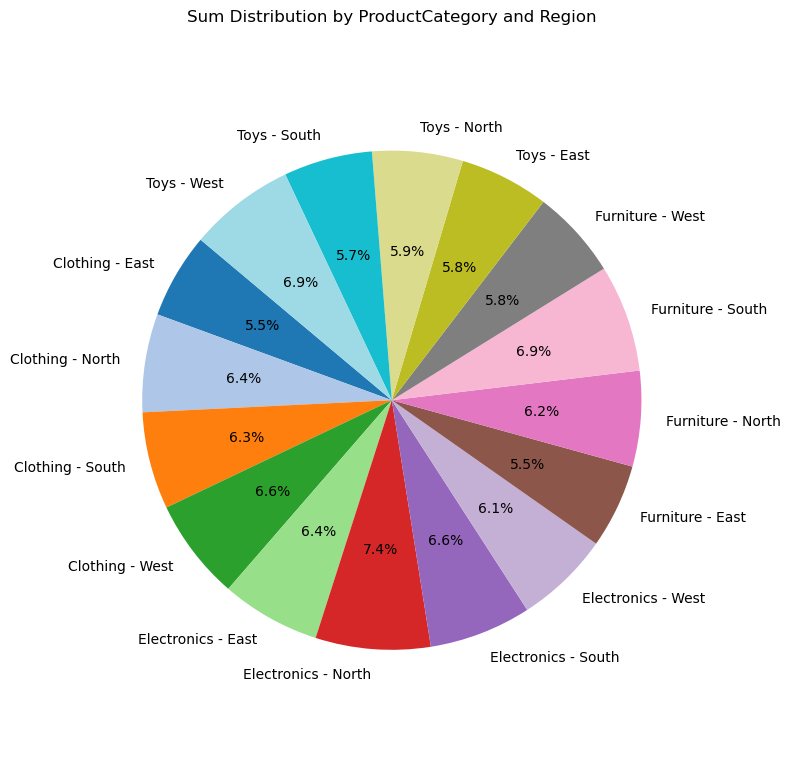

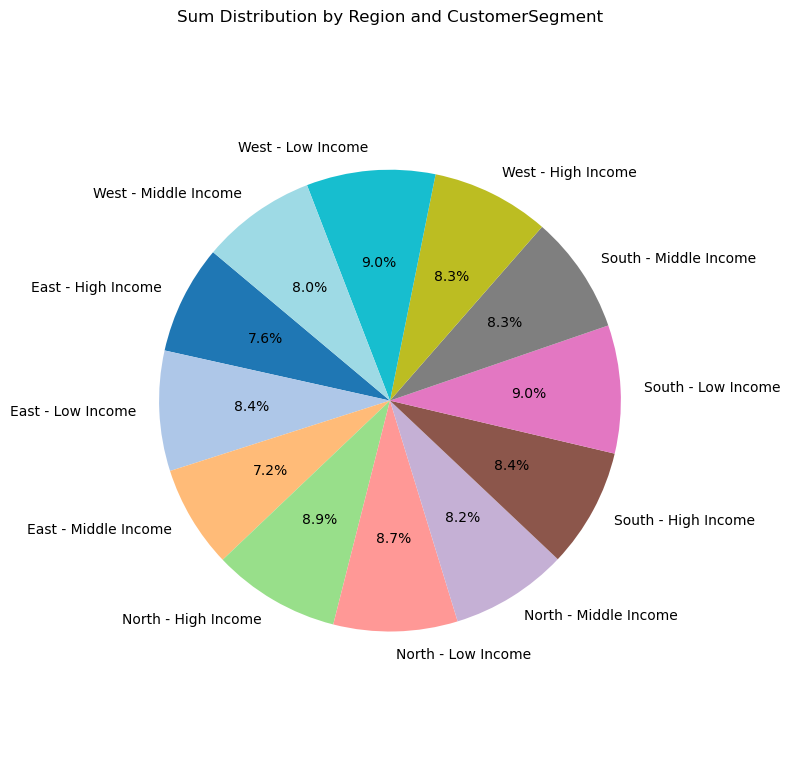

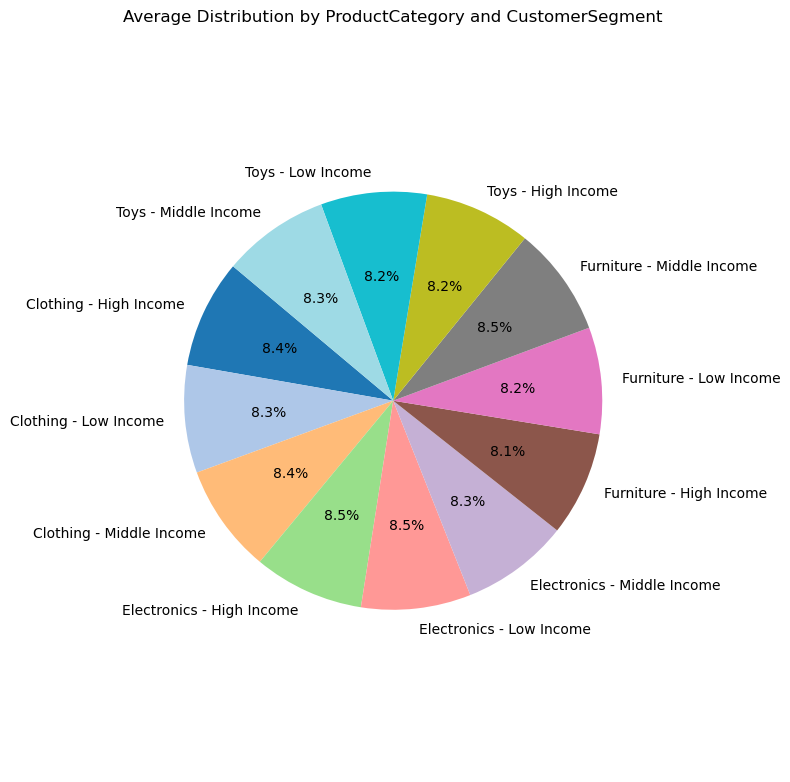

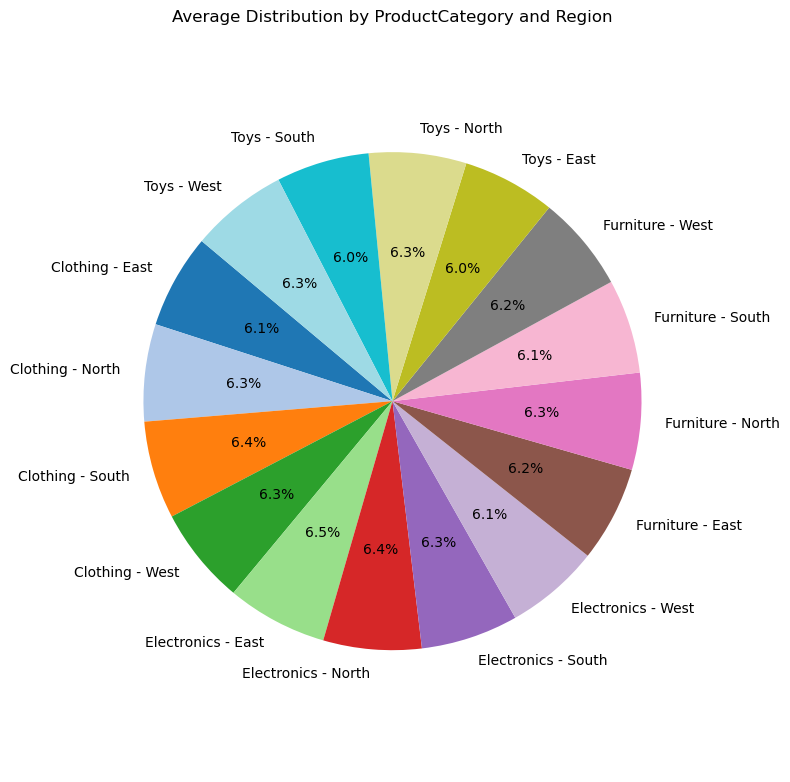

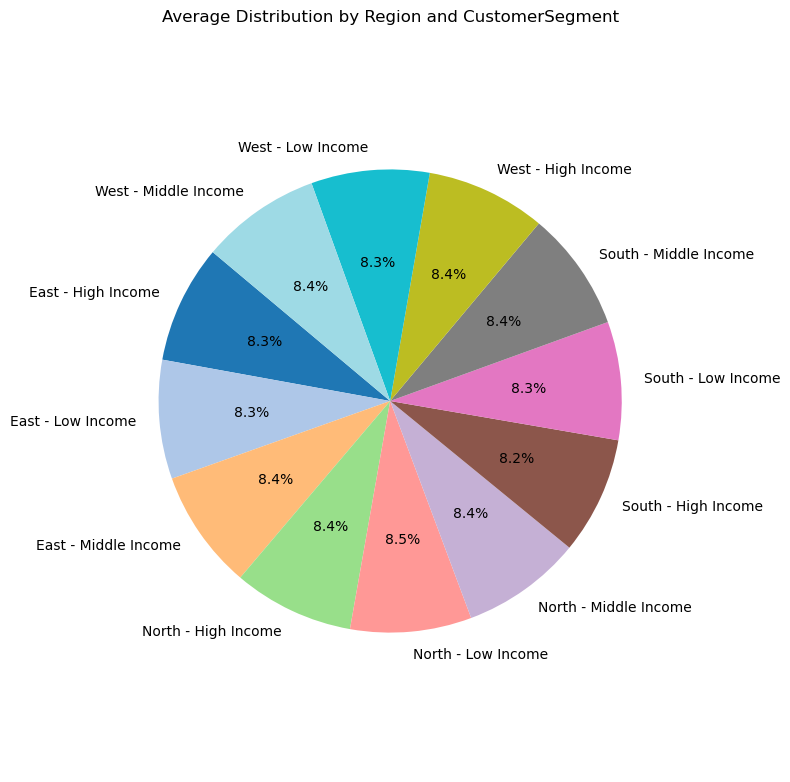

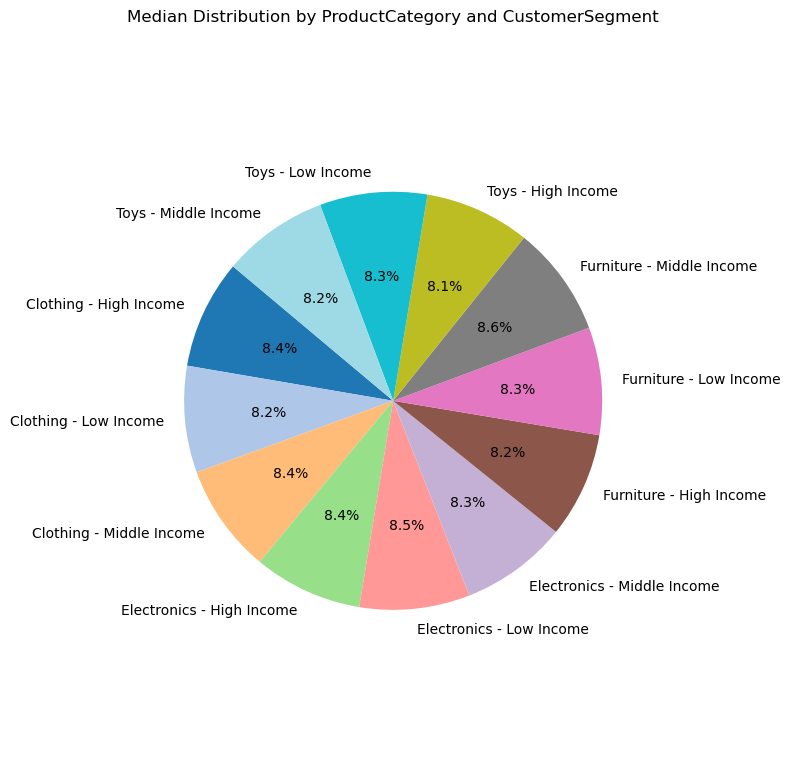

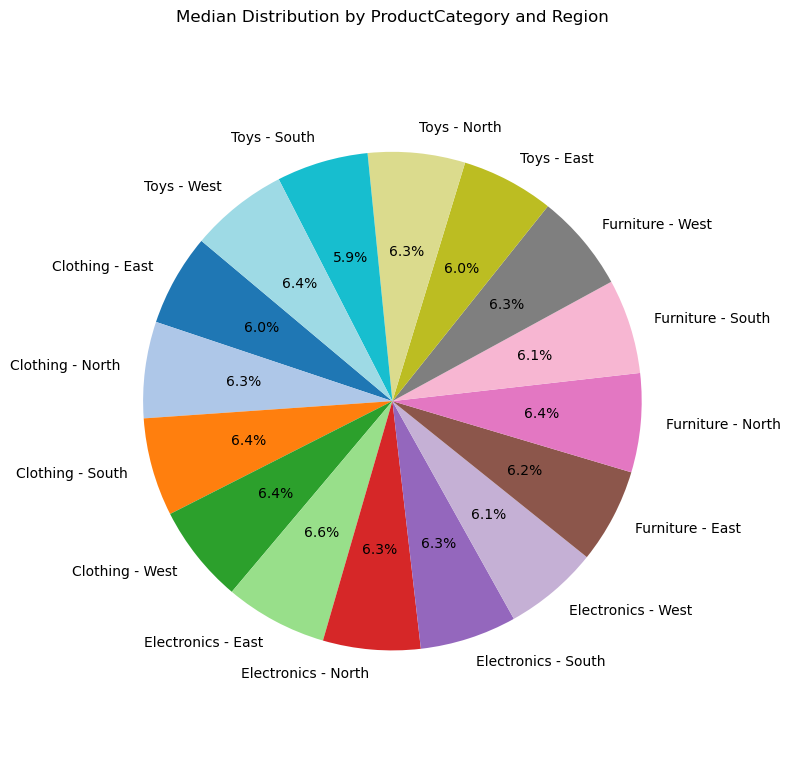

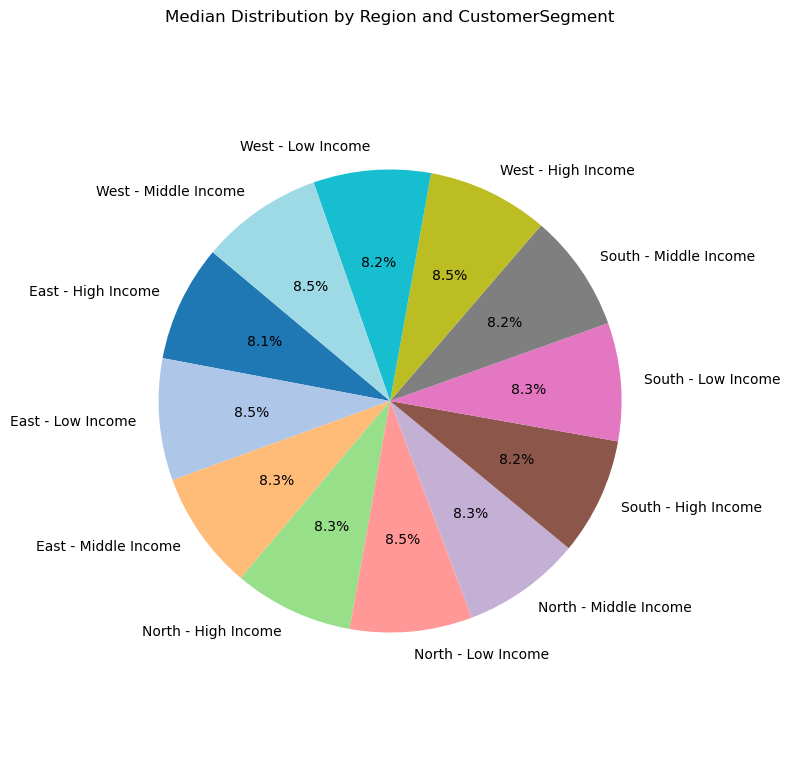

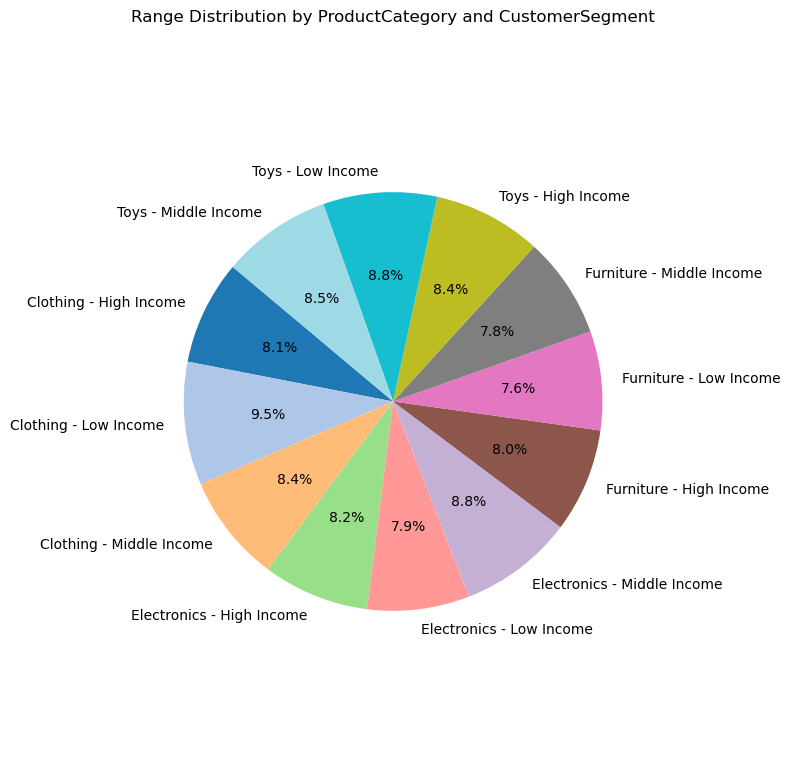

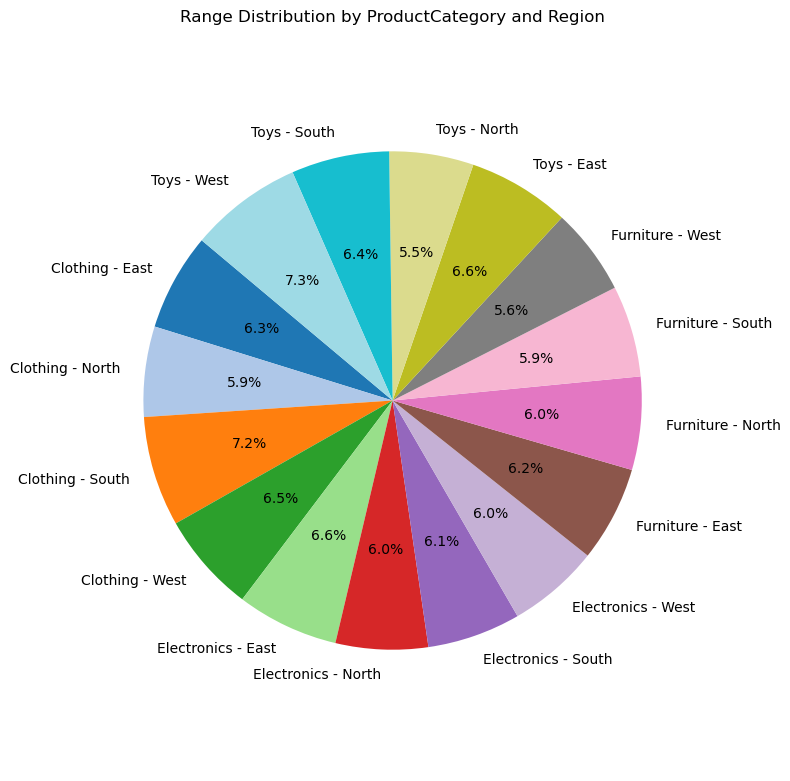

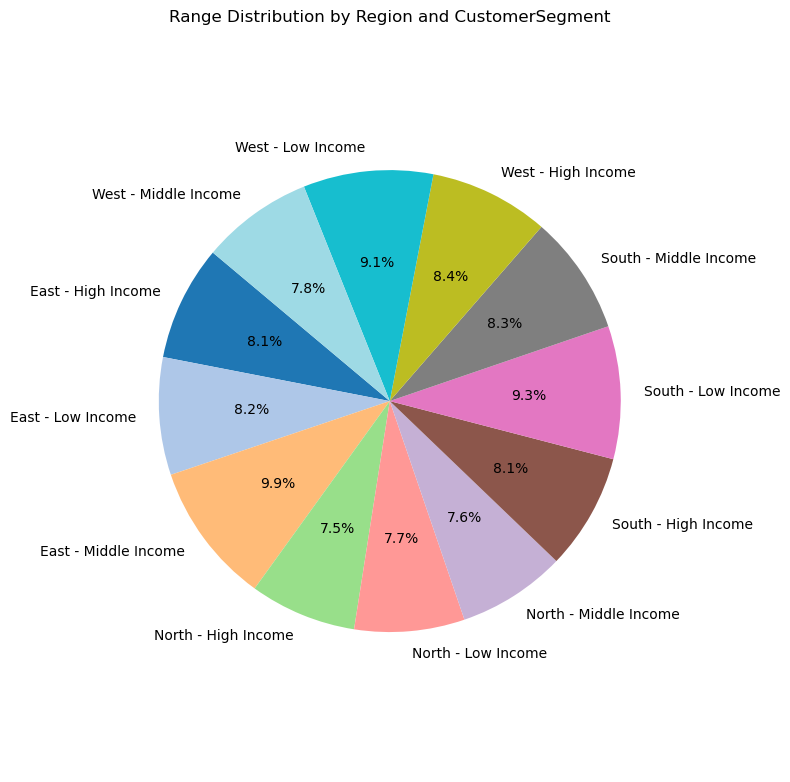

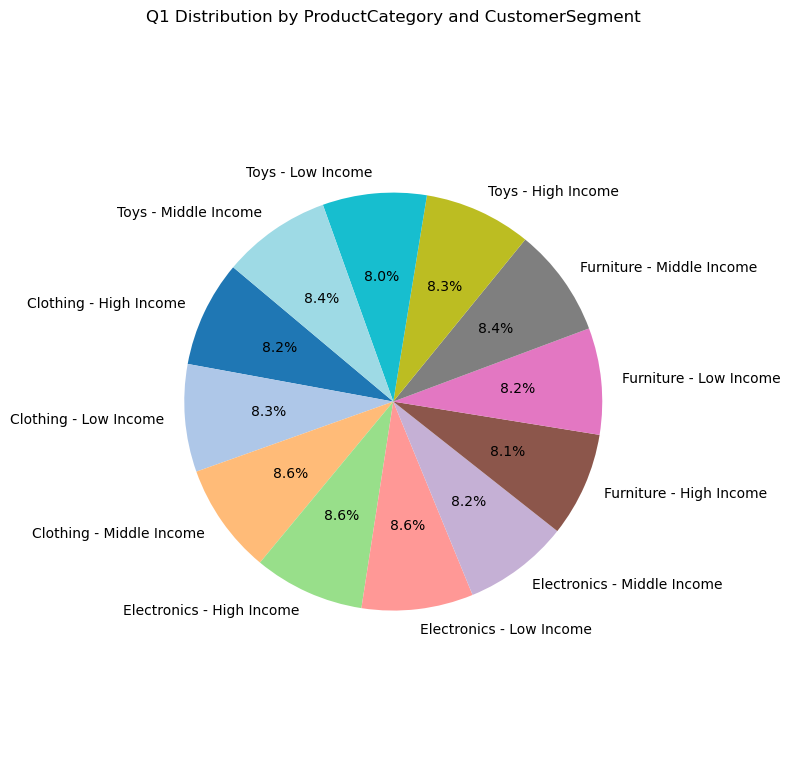

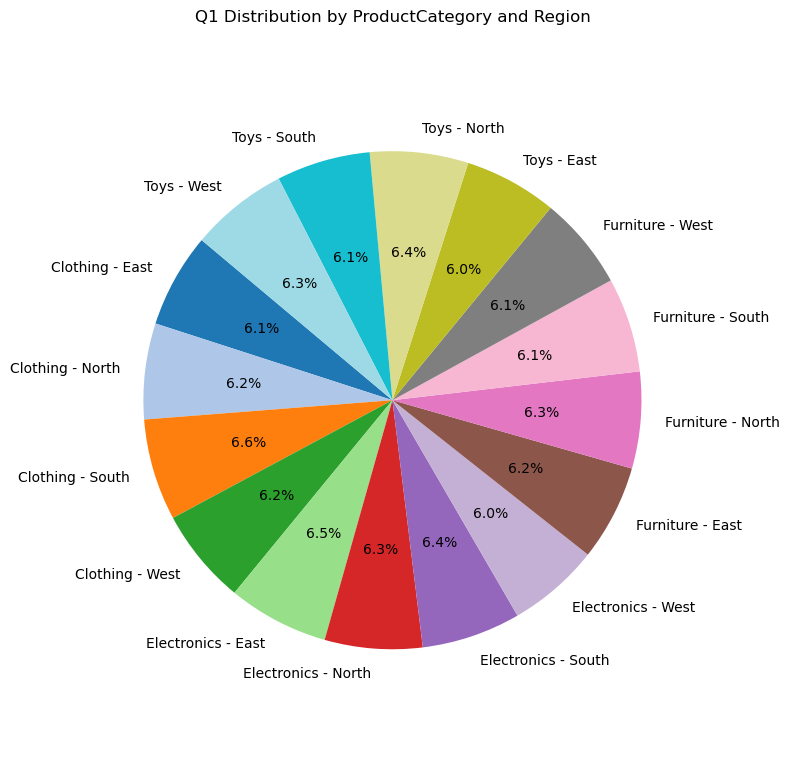

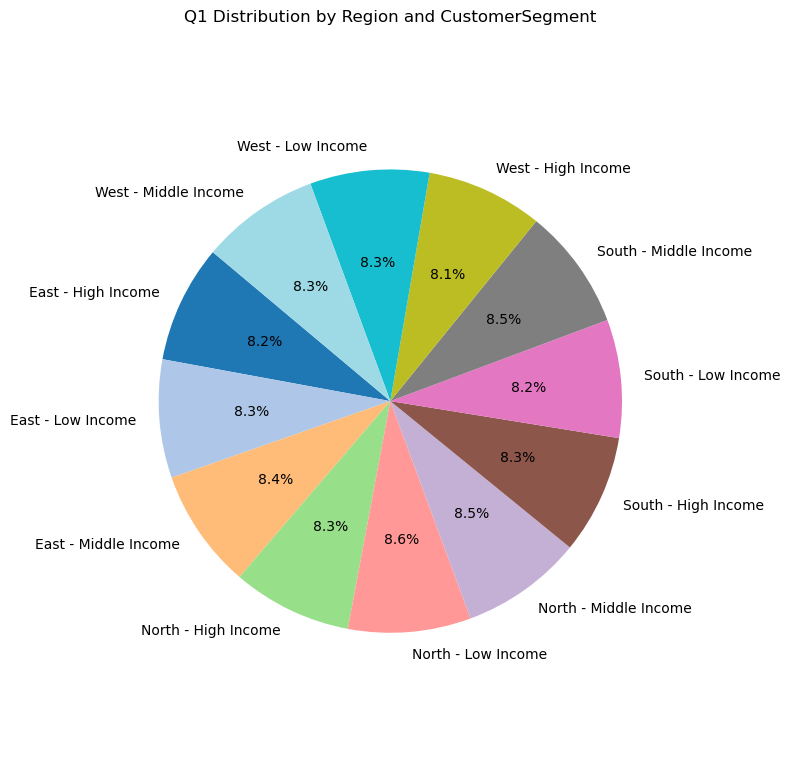

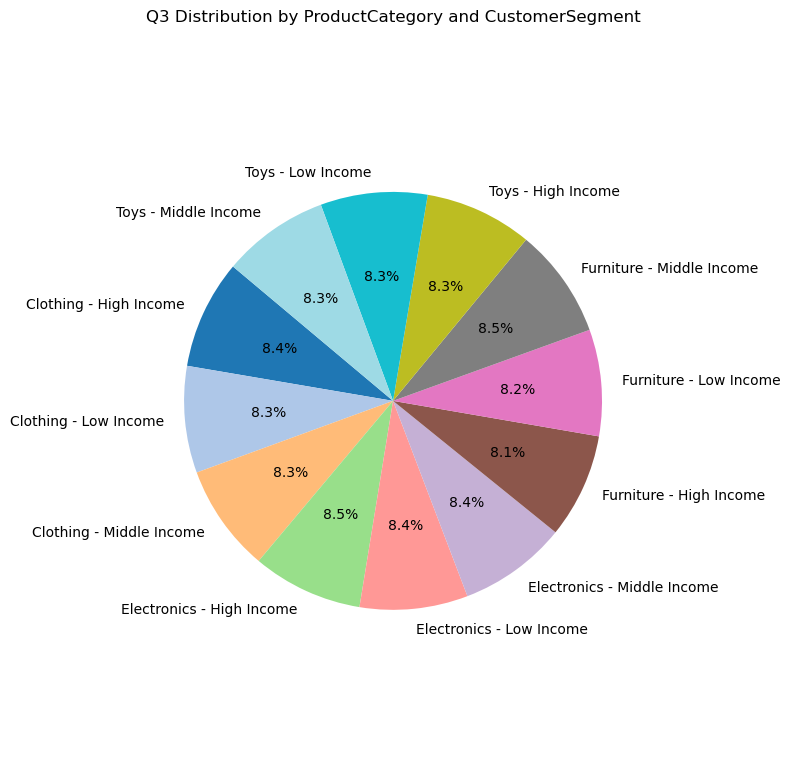

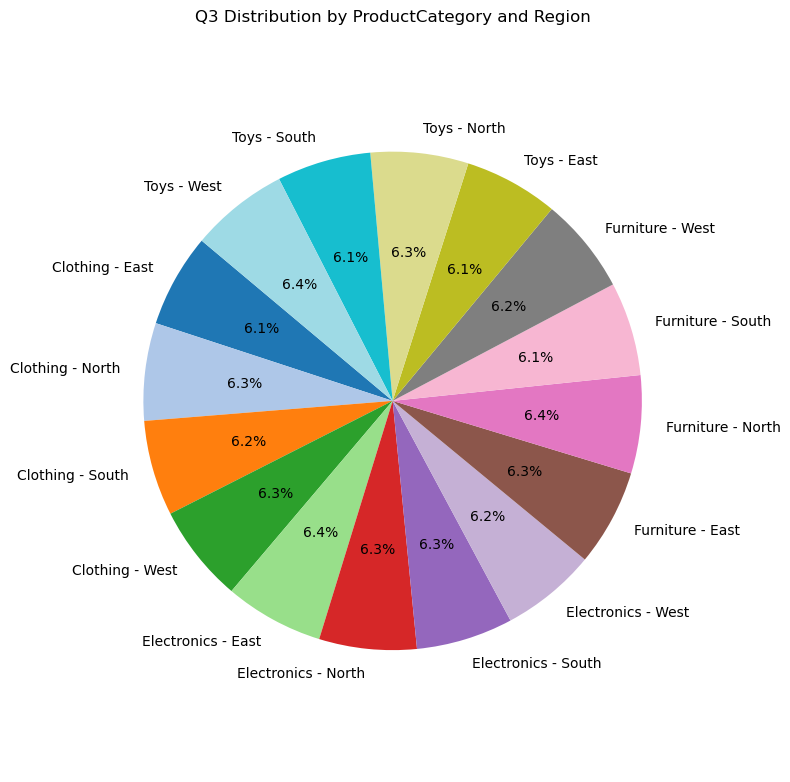

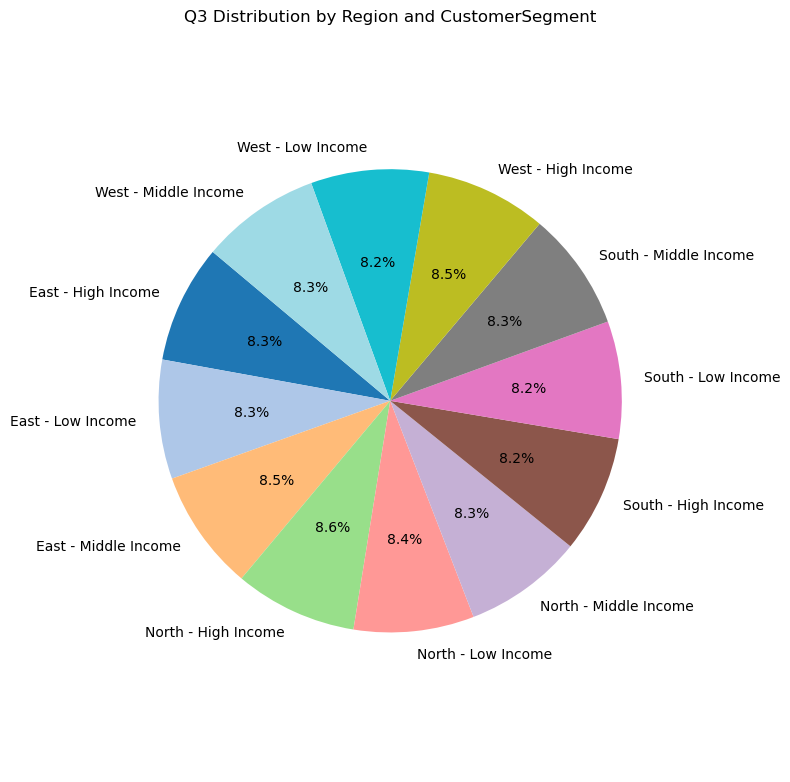

In [1]:
#Pie - Chart
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


df = pd.read_csv("Sales_Data.csv") 


def summarize_by(group_cols):
    grouped = df.groupby(group_cols)['SalesRevenue']
    summary = grouped.agg([
        'sum',
        'mean',
        'median',
        lambda x: x.max() - x.min(),       
        lambda x: x.quantile(0.25),        
        lambda x: x.quantile(0.75)         
    ])
    summary.columns = ['Sum', 'Average', 'Median', 'Range', 'Q1', 'Q3']
    return summary.reset_index()


summary1 = summarize_by(['ProductCategory', 'CustomerSegment'])
summary2 = summarize_by(['ProductCategory', 'Region'])
summary3 = summarize_by(['Region', 'CustomerSegment'])


def get_color_map(labels):
    unique_labels = sorted(set(labels))
    base_colors = plt.cm.get_cmap('tab20', len(unique_labels)).colors
    color_map = {label: base_colors[i % len(base_colors)] for i, label in enumerate(unique_labels)}
    return [color_map[label] for label in labels]


def plot_pie_chart(df, group_cols, value_col):
    labels = df[group_cols[0]].astype(str) + " - " + df[group_cols[1]].astype(str)
    values = df[value_col]


    labels = labels[values > 0]
    values = values[values > 0]

    if len(values) == 0:
        print(f"Skipped {value_col} — no non-zero values.")
        return


    colors = get_color_map(labels)

    plt.figure(figsize=(8, 8))
    plt.pie(values, labels=labels, autopct='%1.1f%%', startangle=140, colors=colors)
    plt.title(f'{value_col} Distribution by {group_cols[0]} and {group_cols[1]}')
    plt.axis('equal')
    plt.tight_layout()
    plt.show()


for col in ['Sum', 'Average', 'Median', 'Range', 'Q1', 'Q3']:
    plot_pie_chart(summary1, ['ProductCategory', 'CustomerSegment'], col)
    plot_pie_chart(summary2, ['ProductCategory', 'Region'], col)
    plot_pie_chart(summary3, ['Region', 'CustomerSegment'], col)


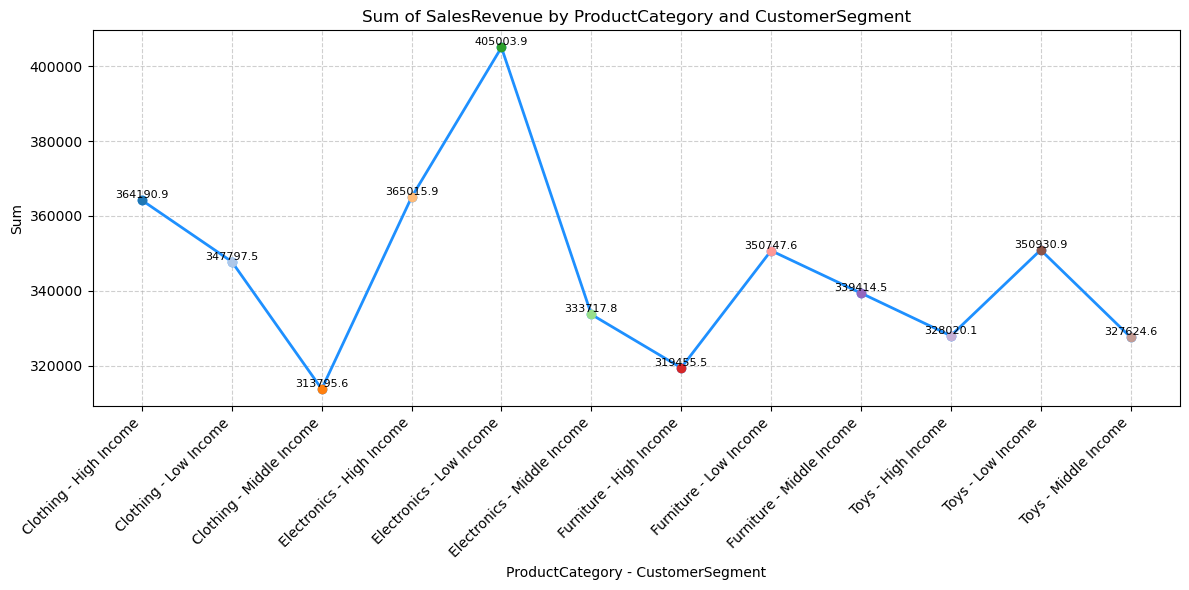

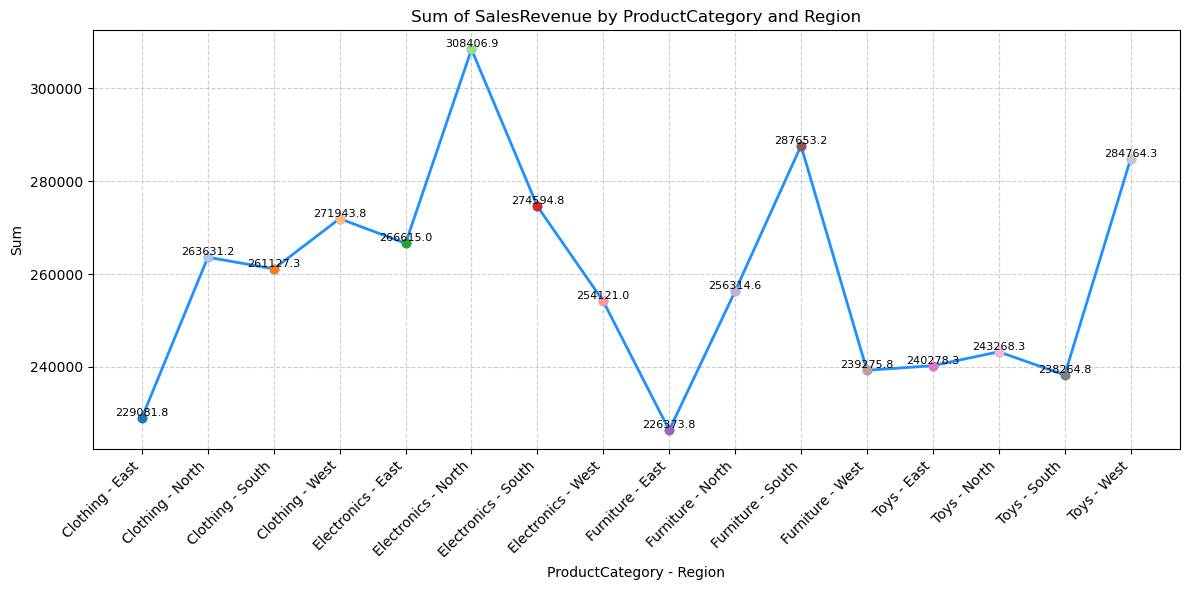

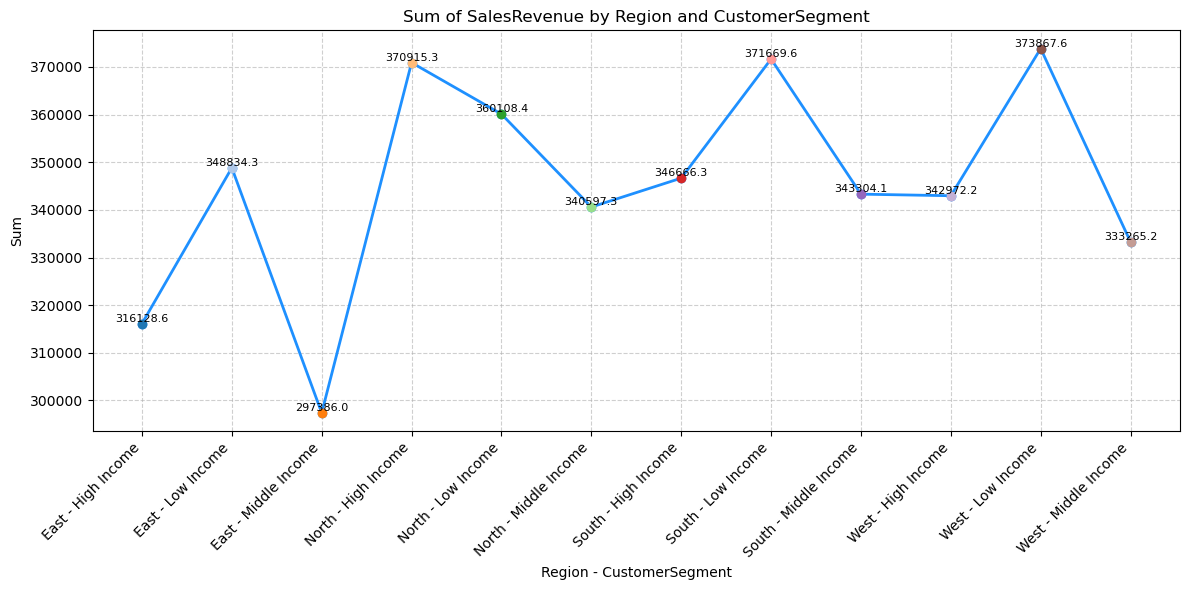

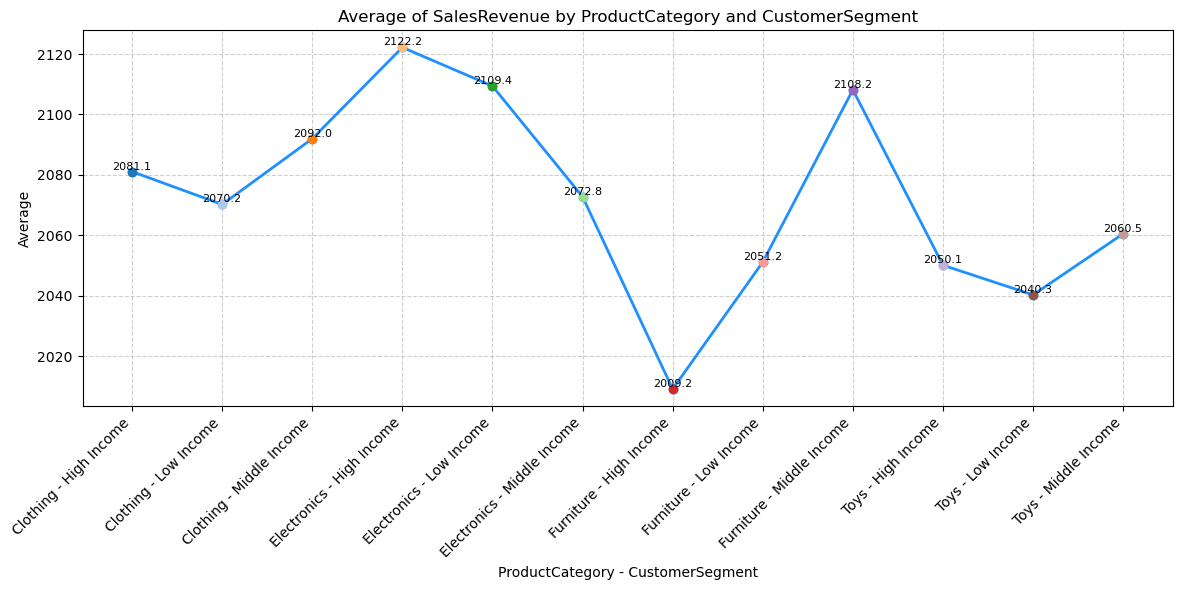

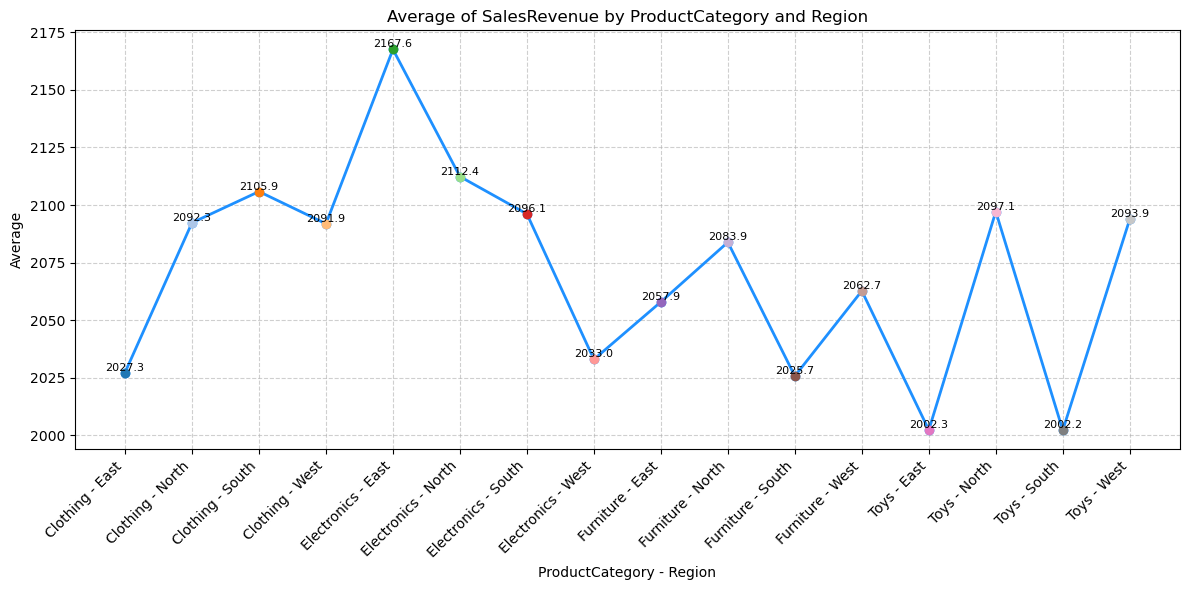

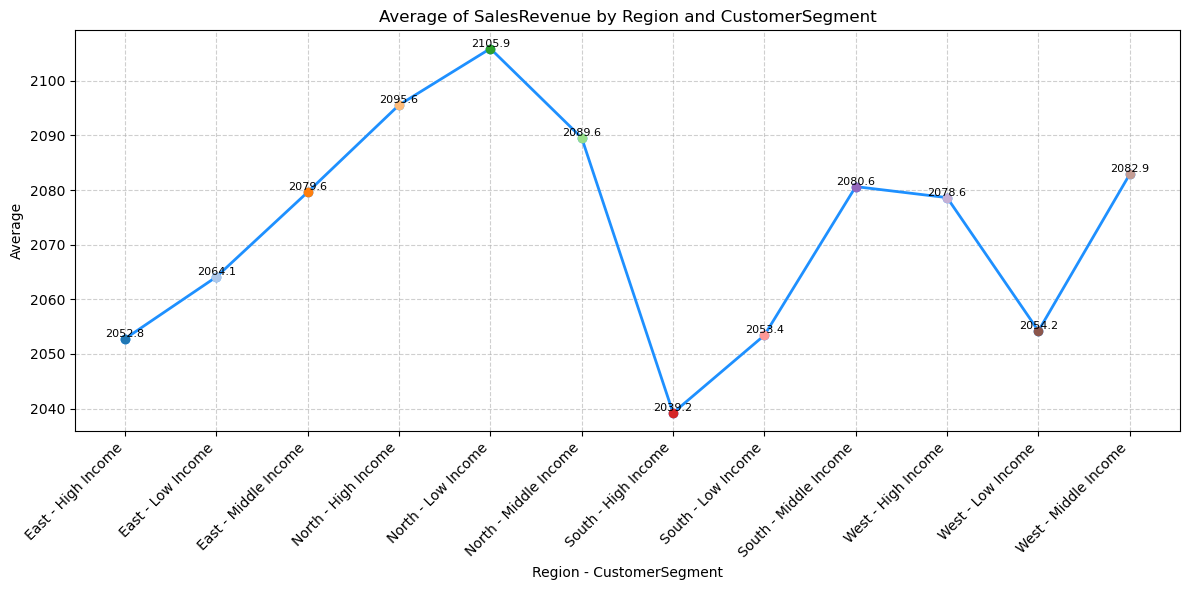

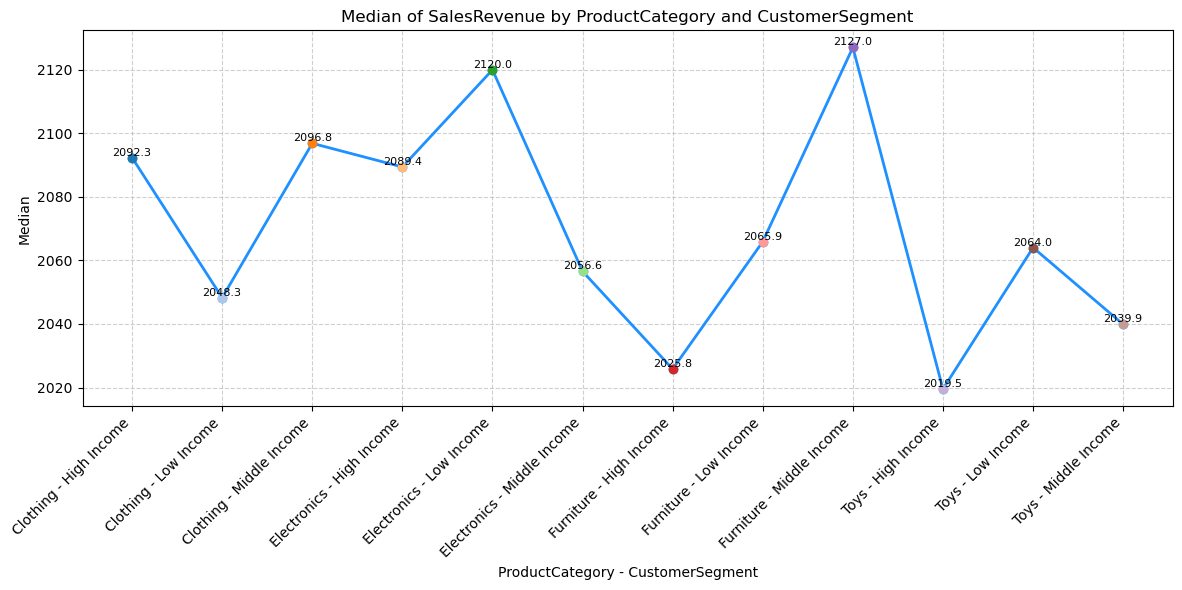

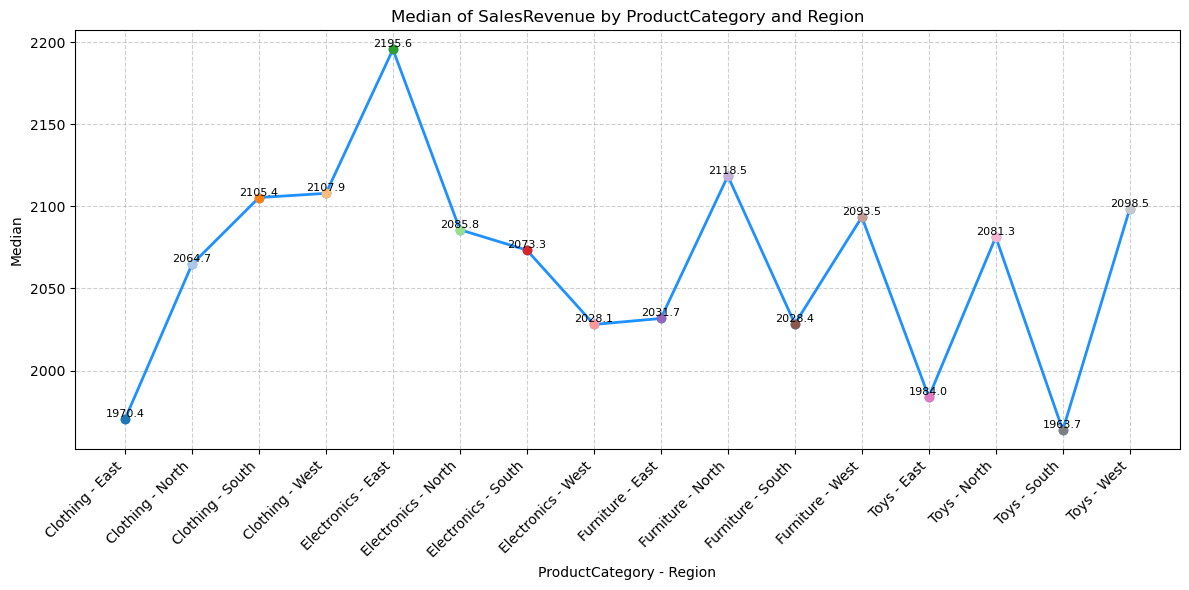

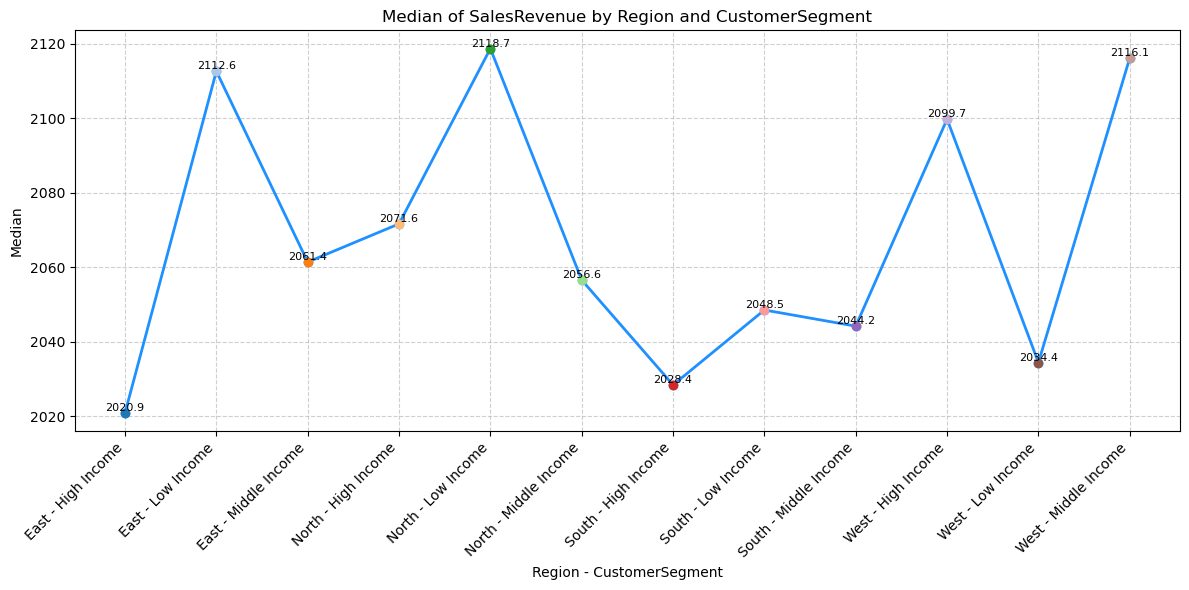

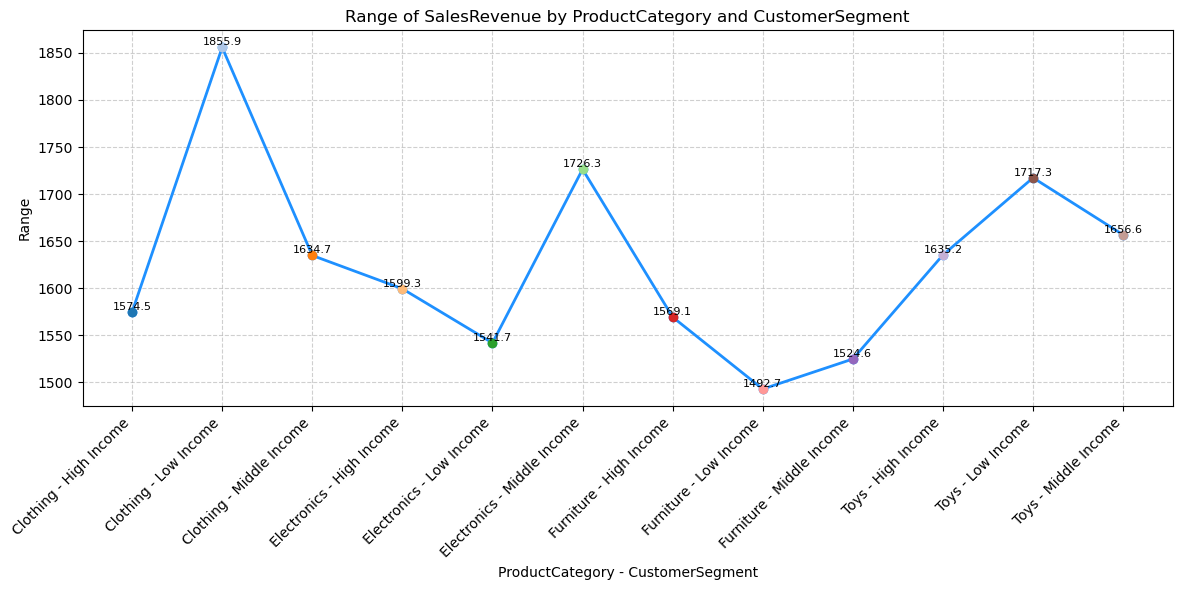

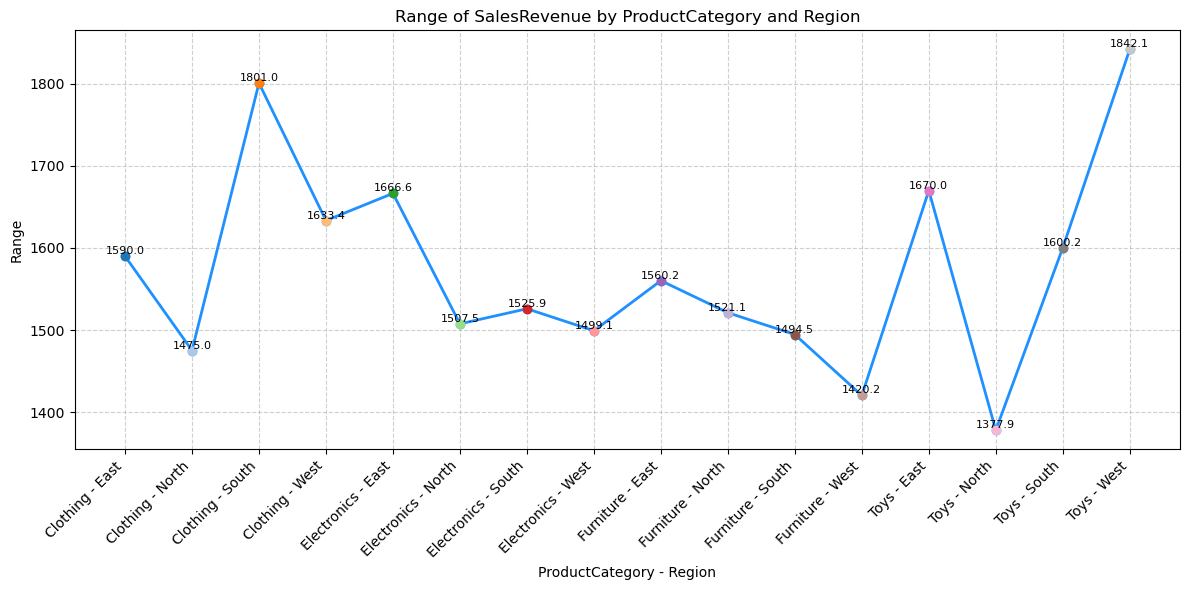

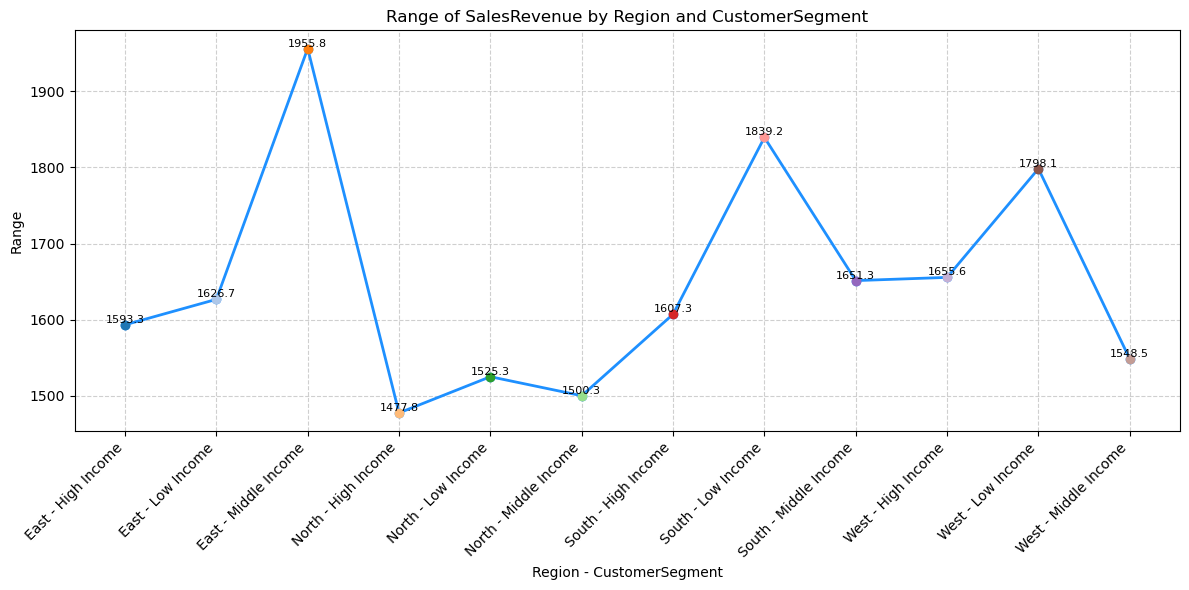

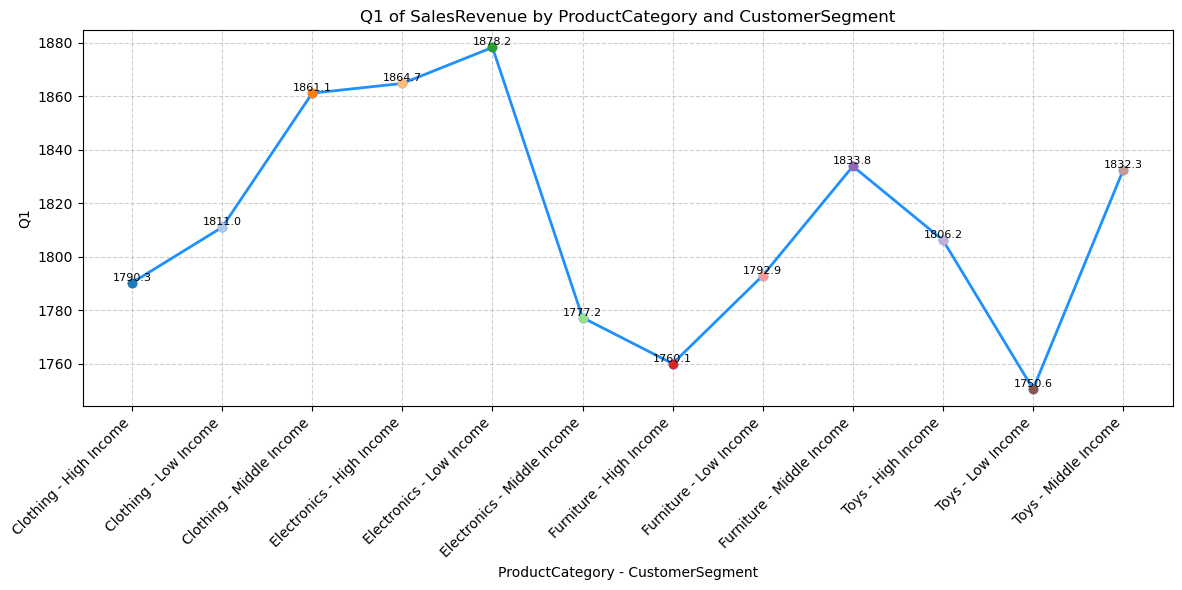

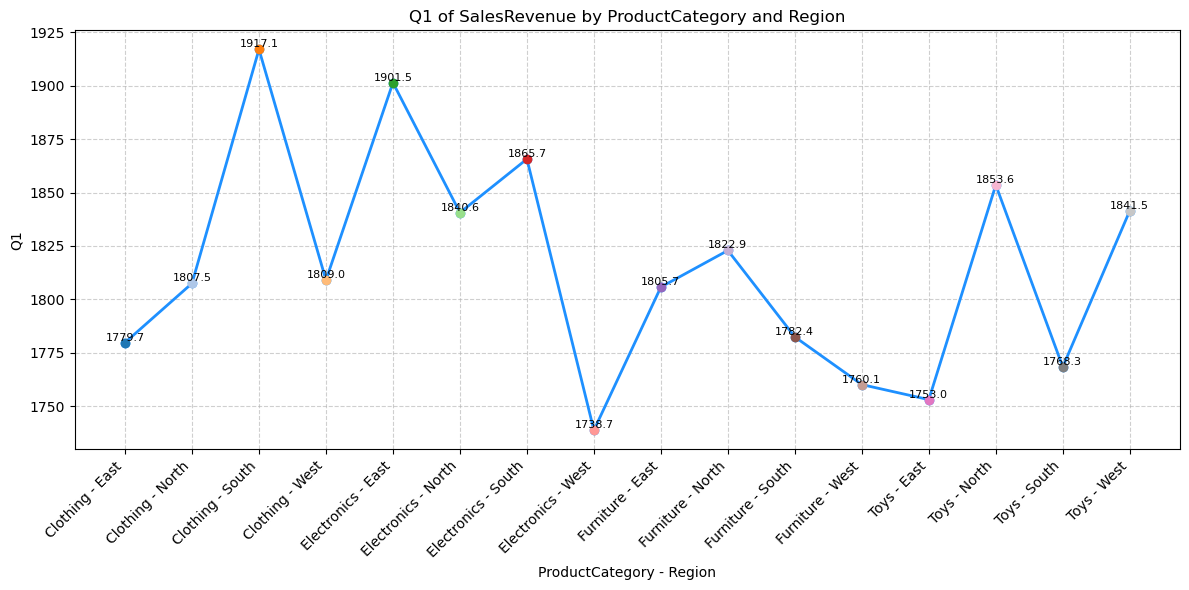

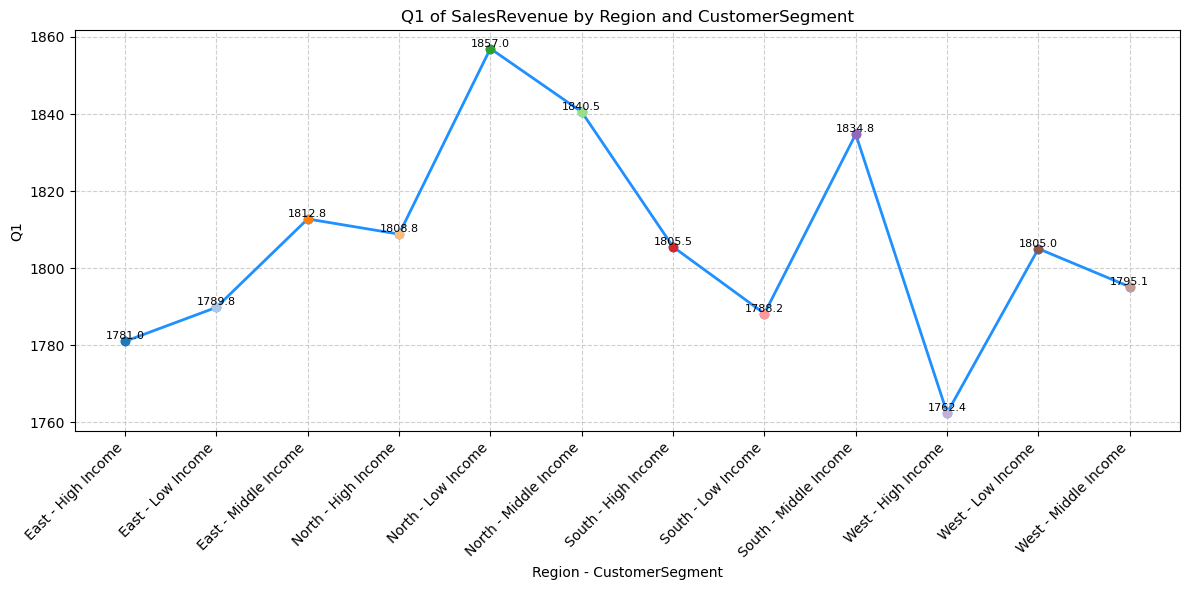

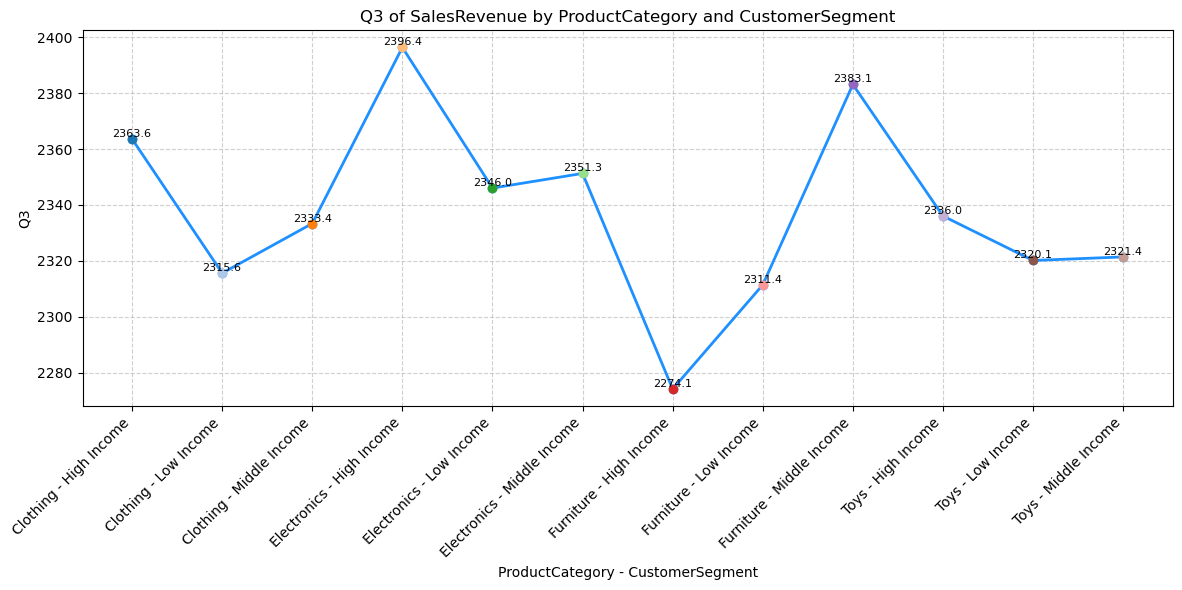

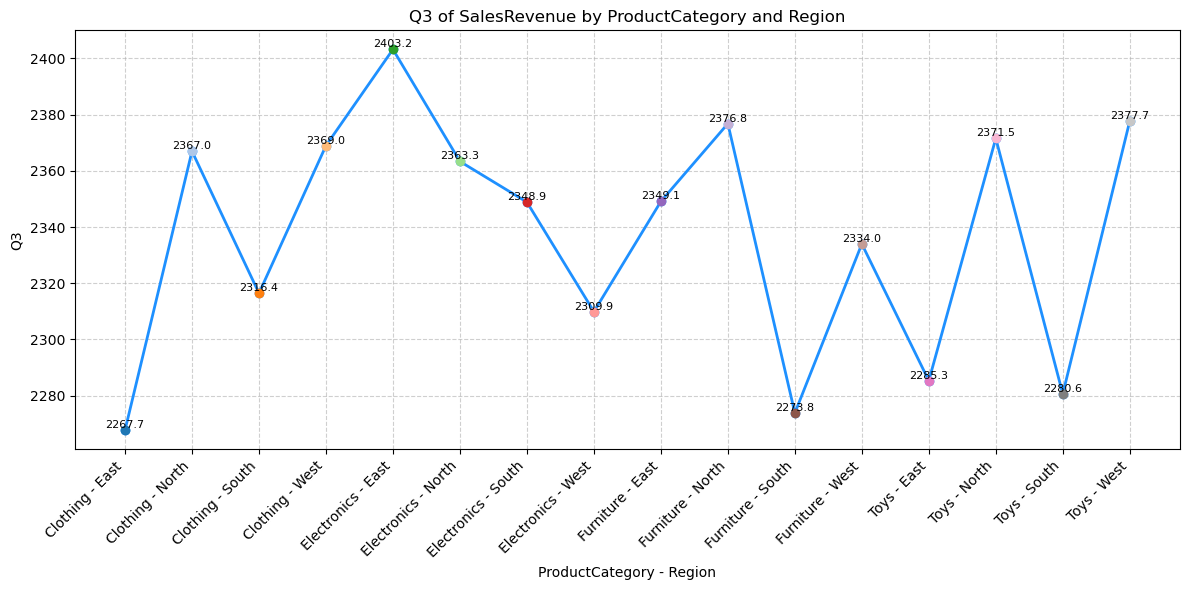

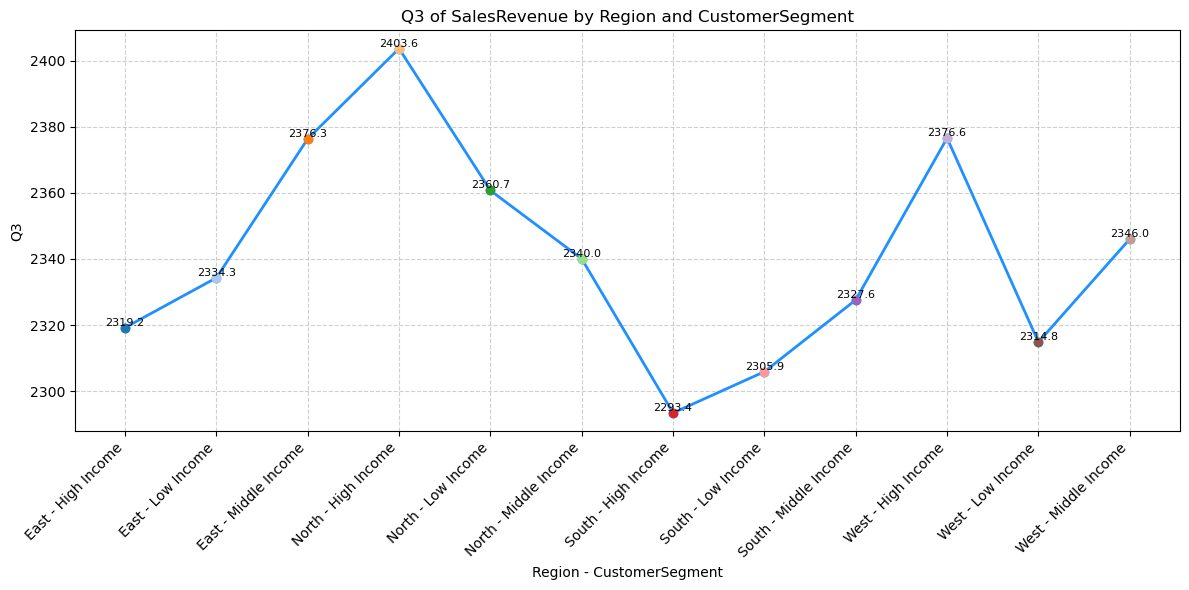

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


df = pd.read_csv("Sales_Data.csv") 


def summarize_by(group_cols):
    grouped = df.groupby(group_cols)['SalesRevenue']
    summary = grouped.agg([
        'sum',
        'mean',
        'median',
        lambda x: x.max() - x.min(),       
        lambda x: x.quantile(0.25),        
        lambda x: x.quantile(0.75)         
    ])
    summary.columns = ['Sum', 'Average', 'Median', 'Range', 'Q1', 'Q3']
    return summary.reset_index()


summary1 = summarize_by(['ProductCategory', 'CustomerSegment'])
summary2 = summarize_by(['ProductCategory', 'Region'])
summary3 = summarize_by(['Region', 'CustomerSegment'])


def get_color_list(n):
    cmap = plt.get_cmap("tab10") if n <= 10 else plt.get_cmap("tab20")
    return [cmap(i % cmap.N) for i in range(n)]


def plot_line_chart(df, group_cols, value_col):
    df = df.copy()
    df['Group'] = df[group_cols[0]].astype(str) + " - " + df[group_cols[1]].astype(str)
    df = df.sort_values('Group')  

    x = np.arange(len(df['Group']))
    y = df[value_col].values
    labels = df['Group'].values

    plt.figure(figsize=(12, 6))
    colors = get_color_list(len(x))

    plt.plot(x, y, marker='o', linestyle='-', color='dodgerblue', linewidth=2)
    for i in range(len(x)):
        plt.plot(x[i], y[i], 'o', color=colors[i])
        plt.text(x[i], y[i], f"{y[i]:.1f}", ha='center', va='bottom', fontsize=8)

    plt.xticks(x, labels, rotation=45, ha='right')
    plt.title(f'{value_col} of SalesRevenue by {group_cols[0]} and {group_cols[1]}')
    plt.xlabel(f'{group_cols[0]} - {group_cols[1]}')
    plt.ylabel(value_col)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()


for col in ['Sum', 'Average', 'Median', 'Range', 'Q1', 'Q3']:
    plot_line_chart(summary1, ['ProductCategory', 'CustomerSegment'], col)
    plot_line_chart(summary2, ['ProductCategory', 'Region'], col)
    plot_line_chart(summary3, ['Region', 'CustomerSegment'], col)
